
# 🌡️ PRAICP-1003 — Air Temperature Time Series Forecasting

### Domain
**Climatology | Weather | Environmental Science**

### Dataset
**Surface Air Temperature Monthly Mean (1982–2020)**

### Records
**462 Monthly Observations**

### Target
**Future Monthly Mean Temperature (°C)**

## 📌 Project Description

This project focuses on analysing and forecasting monthly **Surface Air Temperature (SAT)** using historical temperature observations from **1982 to 2020**.

The project applies **Time-Series Analysis, Statistical Forecasting, Machine Learning, and Deep Learning** techniques to understand long-term temperature trends, seasonal behaviour, autocorrelation, and temporal patterns.

The analysis includes **EDA, stationarity testing, time-series decomposition, ACF/PACF analysis, ARIMA, SARIMA, feature engineering, machine learning models, and LSTM-based forecasting**.

The developed models are evaluated and compared using **MAE, RMSE, MAPE, and R²** metrics.



# **Problem Statement**

Accurate temperature forecasting is important for understanding climate behaviour and supporting decisions in agriculture, energy management, public health, and water-resource planning.

Traditional forecasting methods may not capture all the nonlinear relationships and temporal dependencies present in temperature data.

Therefore, this project investigates different statistical and machine-learning approaches to determine how effectively historical temperature patterns can be used to predict future monthly temperatures.


## 🌡️ What is Surface Air Temperature?

**Surface Air Temperature (SAT)** is the temperature of the air measured at approximately **2 meters above the ground**.

It is an important climate variable used to:

- 🌍 Monitor long-term climate change
- 📈 Analyse temperature trends
- 🌦️ Understand seasonal weather patterns
- 🔮 Forecast future temperature behaviour
- 🌎 Study climate variability


## ❓ Problem Statement

Accurate temperature forecasting is important for understanding climate behaviour and supporting decision-making in agriculture, energy management, public health, and water-resource planning.

Traditional forecasting methods may not capture all the temporal and nonlinear patterns present in temperature data.

Therefore, this project analyses historical temperature data and compares statistical, machine learning, and deep learning approaches for forecasting future monthly temperatures.

## 🎯 Why Does This Problem Matter?

### 🌾 Agriculture
- Crop planning
- Seasonal agricultural decisions
- Frost-warning systems
- Climate-sensitive crop management

### ⚡ Energy
- Heating demand prediction
- Cooling demand prediction
- Energy consumption planning

### 🏥 Public Health
- Heat-stress monitoring
- Early warning systems
- Heat-event preparedness

### 💧 Water Resources
- Reservoir management
- Drought analysis
- Water-resource planning

## 📊 Dataset Description

| Parameter | Value |
|---|---|
| Date Range | January 1982 – June 2020 |
| Duration | Approximately 38 Years |
| Observations | 462 Monthly Records |
| Temperature Range | 25.4°C – 29.5°C |
| Mean Temperature | 27.67°C |
| Standard Deviation | 0.81°C |
| Missing Values | None |
| Warming Trend | Approximately +0.25°C per decade |

## 🎯 Project Objectives

1. Analyse historical monthly Surface Air Temperature data.
2. Identify long-term temperature trends.
3. Analyse monthly seasonal behaviour.
4. Detect possible outliers.
5. Test the stationarity of the time series.
6. Decompose the series into trend, seasonal, and residual components.
7. Analyse autocorrelation using ACF and PACF.
8. Develop ARIMA and SARIMA forecasting models.
9. Perform temporal feature engineering.
10. Develop multiple machine learning models.
11. Develop an LSTM-based forecasting model.
12. Develop an improved 12-step sequence LSTM.
13. Compare model performance using MAE, RMSE, MAPE, and R².
14. Perform TimeSeriesSplit cross-validation.
15. Perform residual analysis.
16. Perform walk-forward validation.
17. Generate future temperature forecasts.

## 🔬 Analysis Pipeline

**Data Loading**
↓
**Data Preprocessing**
↓
**Exploratory Data Analysis (EDA)**
↓
**Trend Analysis**
↓
**Rolling Statistics**
↓
**Seasonal Analysis**
↓
**Outlier Detection**
↓
**Stationarity Testing**
↓
**Differencing**
↓
**Time-Series Decomposition**
↓
**ACF / PACF Analysis**
↓
**Train-Test Split**
↓
**ARIMA**
↓
**SARIMA**
↓
**Feature Engineering**
↓
**Machine Learning Models**
↓
**LSTM**
↓
**12-Step Sequence LSTM**
↓
**Model Comparison**
↓
**Cross-Validation**
↓
**Residual Analysis**
↓
**Walk-Forward Validation**
↓
**Future Forecasting**

In [ ]:
# Import all the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
from  matplotlib.ticker import MaxNLocator
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split,TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller,kpss,acf,pacf
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

**Load the data**

In [ ]:
data = pd.read_csv('/surface-air-temperature-monthly-mean.csv')
data.shape


(462, 2)

In [ ]:
data.head()

,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


In [ ]:
data.columns

Index(['month', 'mean_temp'], dtype='object')

In [ ]:
# Check the information of the data
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   month      462 non-null    object 
 1   mean_temp  462 non-null    float64
dtypes: float64(1), object(1)
memory usage: 7.3+ KB


In [ ]:
# Check for null values
data.isnull().sum()

,0
month,0
mean_temp,0


In [ ]:
# Check for duplicates
data.duplicated().sum()


np.int64(0)

In [ ]:
data.describe()

,mean_temp
count,462.000000
mean,27.665152
std,0.808186
min,25.400000
25%,27.100000
50%,27.700000
75%,28.300000
max,29.500000


In [ ]:

data.dtypes

,0
month,object
mean_temp,float64


In [ ]:
# Check for Descriptive statistics and additional stats
print('\n Descriptive Statistics')
print('-'*50)
series = data['mean_temp']
desc = series.describe()
for stat, val in desc.items():
  print(f" {stat:8s} : {val:.4f}°C ")
# Additional stats
print(f"\n Skewness : {series.skew():.4f}")
print(f" Kurtosis : {series.kurtosis():.4f}")
print(f" Range : {series.max() - series.min():.2f} °C")
print(f" Variance : {series.var():.4f}")


 Descriptive Statistics
--------------------------------------------------
 count    : 462.0000°C 
 mean     : 27.6652°C 
 std      : 0.8082°C 
 min      : 25.4000°C 
 25%      : 27.1000°C 
 50%      : 27.7000°C 
 75%      : 28.3000°C 
 max      : 29.5000°C 

 Skewness : -0.2084
 Kurtosis : -0.4103
 Range : 4.10 °C
 Variance : 0.6532


**Convert object column to date & time columns**



In [ ]:
data['month'] = pd.to_datetime(data['month'])
data.set_index('month',inplace=True)


In [ ]:
data.rename(columns = {'mean_temp' : 'Temperature'}, inplace = True)
data.head(5)

,Temperature
month,
1982-01-01,25.9
1982-02-01,27.1
1982-03-01,27.2
1982-04-01,27.0
1982-05-01,28.0


## 📈 Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand the structure and behaviour of the temperature series.

The analysis includes:

- Temperature distribution
- Historical temperature trend
- Rolling mean analysis
- Monthly temperature distribution
- Yearly temperature patterns
- Correlation analysis
- Outlier detection

The analysis helps identify long-term trends, seasonal behaviour, variability, and unusual observations in the temperature series.

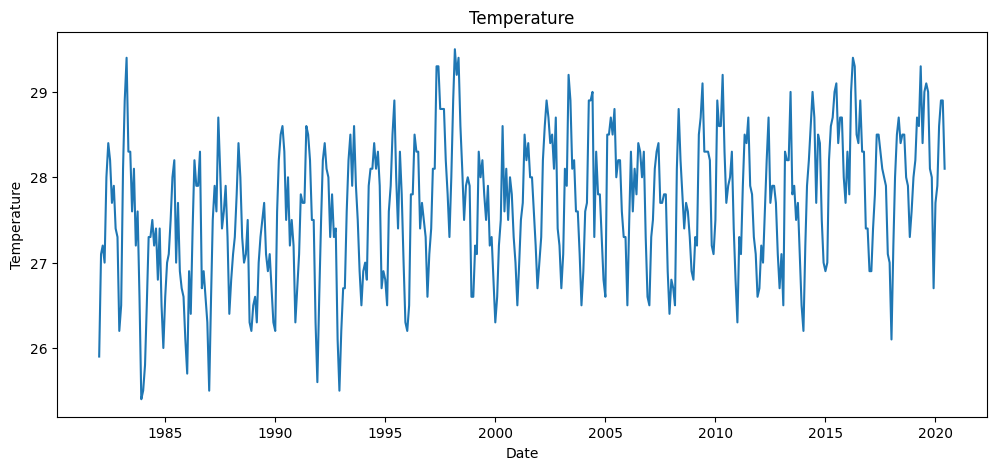

In [ ]:

# Plot for Temperature.
plt.figure(figsize = (12,5))
plt.plot(data.index,data['Temperature'])
plt.title('Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.show()

Insights:

Temperature ranges from 25.4°C to 29.5°C over 38 years (1982-2020).
From the plot, a clear upward warm trend of +0.245°C per decade is visible.
The 12 month rolling mean smooths out seasonal spike and confirm the long term warm direction.
The 60 month(5 year) rolling mean shows a dip around 1984-1992, and there is a peak near 1997-1998.
There is no missing values or gaps in the series.

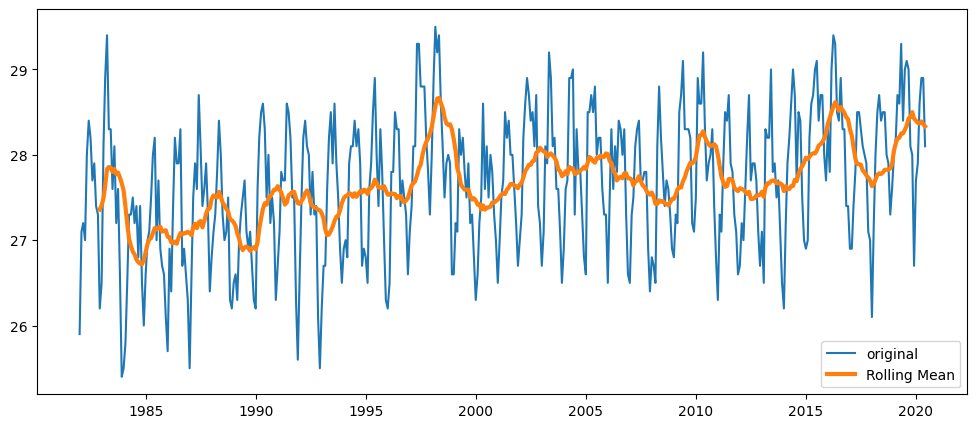

In [ ]:
# plot for Rolling mean
data['Rolling_Mean'] = data['Temperature'].rolling(window = 12).mean()
plt.figure(figsize = (12,5))
plt.plot(data['Temperature'], label = 'original')
plt.plot(data['Rolling_Mean'], label = 'Rolling Mean', linewidth = 3)
plt.legend()
plt.show()


Insights:



* This plot shows a smoothed version of the original temperature, highlighting the underlying pattern by reducing short-term fluctuations.
*   The rolling mean reveals the underlying warming trend in the series. Short-term fluctuations are smoothed, making the long-term direction clearer — this does not imply stationarity, which is tested separately using ADF and KPSS tests.



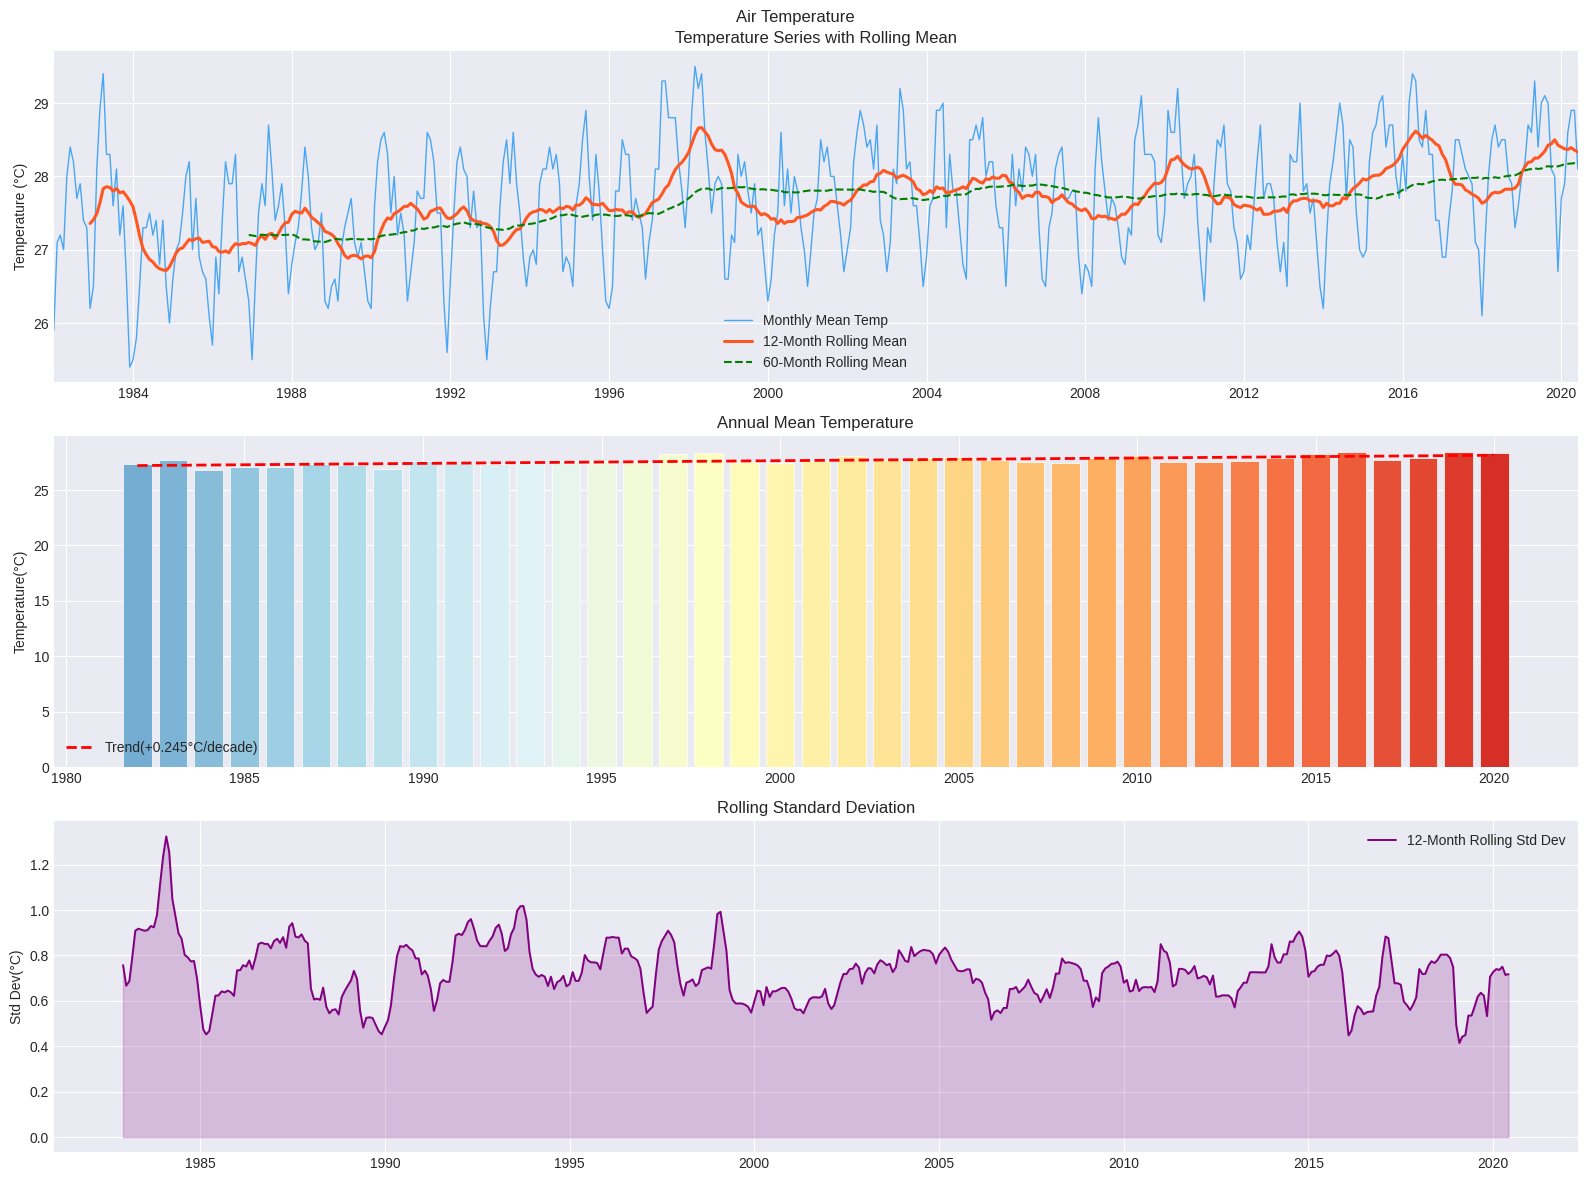

In [ ]:
# Annual Mean Temperature.
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
FIGSIZE = (14,5)
COLOR = '#2196F3'
ACCENT = '#FF5722'
fig,axes = plt.subplots(3,1, figsize = (16, 12))
fig.suptitle('Air Temperature')

# Redefine series to use the updated data DataFrame with DatetimeIndex
series = data['Temperature']

# Plot for Raw series and Rolling Mean
ax = axes[0]
ax.plot(series.index, series, color = COLOR, linewidth=1.0, alpha=0.8,label='Monthly Mean Temp')
ax.plot(series.rolling(12).mean(), color = ACCENT, linewidth = 2.2,label = '12-Month Rolling Mean')
ax.plot(series.rolling(60).mean(),color = 'green',linestyle='--',label='60-Month Rolling Mean')
ax.set_title('Temperature Series with Rolling Mean')
ax.set_ylabel('Temperature (°C)')
ax.legend()
ax.set_xlim(series.index[0],series.index[-1])
# Plot-2 Annual Mean Temperature
ax2 = axes[1]
annual = series.resample('YE').mean()
colors_bar = plt.cm.RdYlBu_r(np.linspace(0.2,0.9, len(annual)))
bars = ax2.bar(annual.index.year,annual.values,color = colors_bar,edgecolor = 'white',linewidth=0.5)
z = np.polyfit(annual.index.year,annual.values,1)
ax2.plot(annual.index.year, np.poly1d(z)(annual.index.year),
         color = 'red',linewidth = 2,linestyle = '--',label = f'Trend(+{z[0]*10:.3f}°C/decade)')
ax2.set_title('Annual Mean Temperature')
ax2.set_ylabel('Temperature(°C)')
ax2.legend()
# plot-3 Rolling Standard Deviation
ax3 = axes[2]
ax3.plot(series.rolling(12).std(),color='purple',linewidth=1.4, label = '12-Month Rolling Std Dev')
ax3.fill_between(series.index,series.rolling(12).std(),alpha = 0.2,color='purple')
ax3.set_title('Rolling Standard Deviation')
ax3.set_ylabel('Std Dev(°C)')
ax3.legend()
plt.tight_layout()
plt.savefig('EDA_Overview.png',dpi = 150, bbox_inches='tight')
plt.show()


Insights:

*  April, May, June are the warmest months (median ~28.5-29°C).

*   January and December are the coolest months(median ~26.5-27°C)

*  May and June shows the highest upper whiskers (i.e, occasional extreme heat events in early summer)
*   December shows lowest median with tight IQR → most consistent cool month.

*   This confirms a strong, repeating seasonal cycle every year.




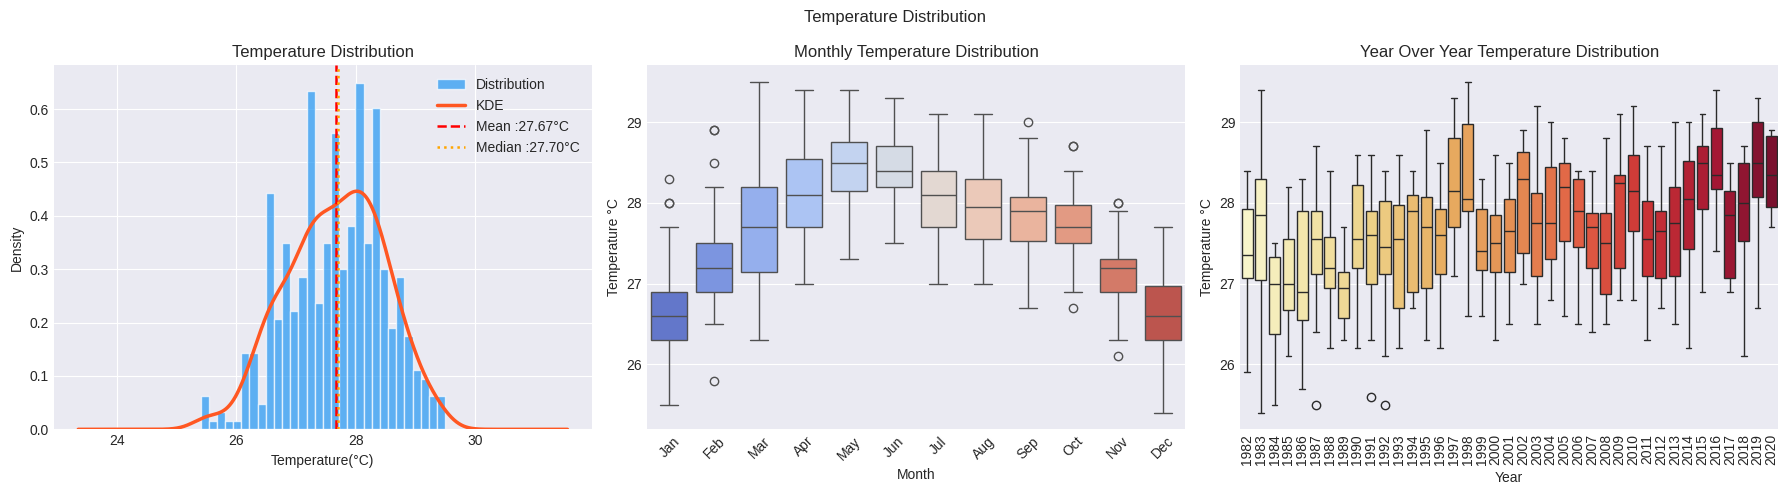

In [ ]:
# Plot for Histogram and monthly box plot
fig, axes = plt.subplots(1,3,figsize = (18,5))
fig.suptitle('Temperature Distribution')
ax1 = axes[0]
ax1.hist(series, bins = 30, color = COLOR, alpha = 0.7, edgecolor = 'white', density = True, label = 'Distribution')
series.plot(kind = 'kde',ax = ax1, color = ACCENT, linewidth = 2.5, label = 'KDE')
ax1.axvline(series.mean(),color = 'red',linestyle = '--',linewidth = 1.8,label = f'Mean :{series.mean():.2f}°C')
ax1.axvline(series.median(),color = 'orange',linestyle = ':',linewidth = 1.8, label = f'Median :{series.median():.2f}°C')
ax1.set_title('Temperature Distribution')
ax1.set_xlabel('Temperature(°C)')
ax1.legend()
# Box plot for Monthly Temperature
ax2 = axes[1]
monthly_df = pd.DataFrame({
    'temp': series.values,
    'month': series.index.month
})
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_df['month_name'] = monthly_df['month'].apply(lambda x: month_names[x-1])
monthly_df['month_name'] = pd.Categorical(monthly_df['month_name'],categories=month_names, ordered = True)
monthly_df.sort_values('month_name',inplace = True)
sns.boxplot(data = monthly_df, x = 'month_name',y = 'temp',ax = ax2, palette = 'coolwarm')
ax2.set_title('Monthly Temperature Distribution')
ax2.set_xlabel('Month')
ax2.set_ylabel('Temperature °C')
ax2.tick_params(axis = 'x',rotation = 45)
# Box plot for yearly Temperature
ax3 = axes[2]
yearly_df = pd.DataFrame({'temp': series.values, 'year': series.index.year})
year_means = yearly_df.groupby('year')['temp'].mean()
decade_colors = ['#1976D2']*10 + ['#388E3C']*10 +['#C62828']*10
sns.boxplot(data=yearly_df, x = 'year',y = 'temp',ax = ax3,
            palette = sns.color_palette('YlOrRd', n_colors = len(yearly_df['year'].unique())))
ax3.set_title('Year Over Year Temperature Distribution')
ax3.set_xlabel('Year')
ax3.set_ylabel('Temperature °C')
ax3.tick_params(axis = 'x',rotation = 90)
plt.tight_layout()
plt.savefig('Temperature Distribution.png',dpi = 150, bbox_inches = 'tight')
plt.show()

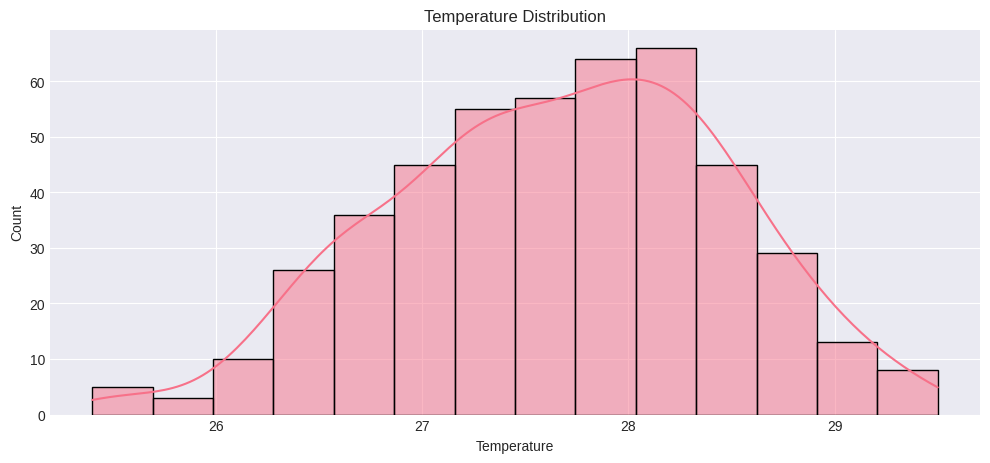

In [ ]:
# Distribution plot for Temperature
plt.figure(figsize=(12,5))
sns.histplot(data['Temperature'],kde = True)
plt.title('Temperature Distribution')
plt.show()

**HeatMap**

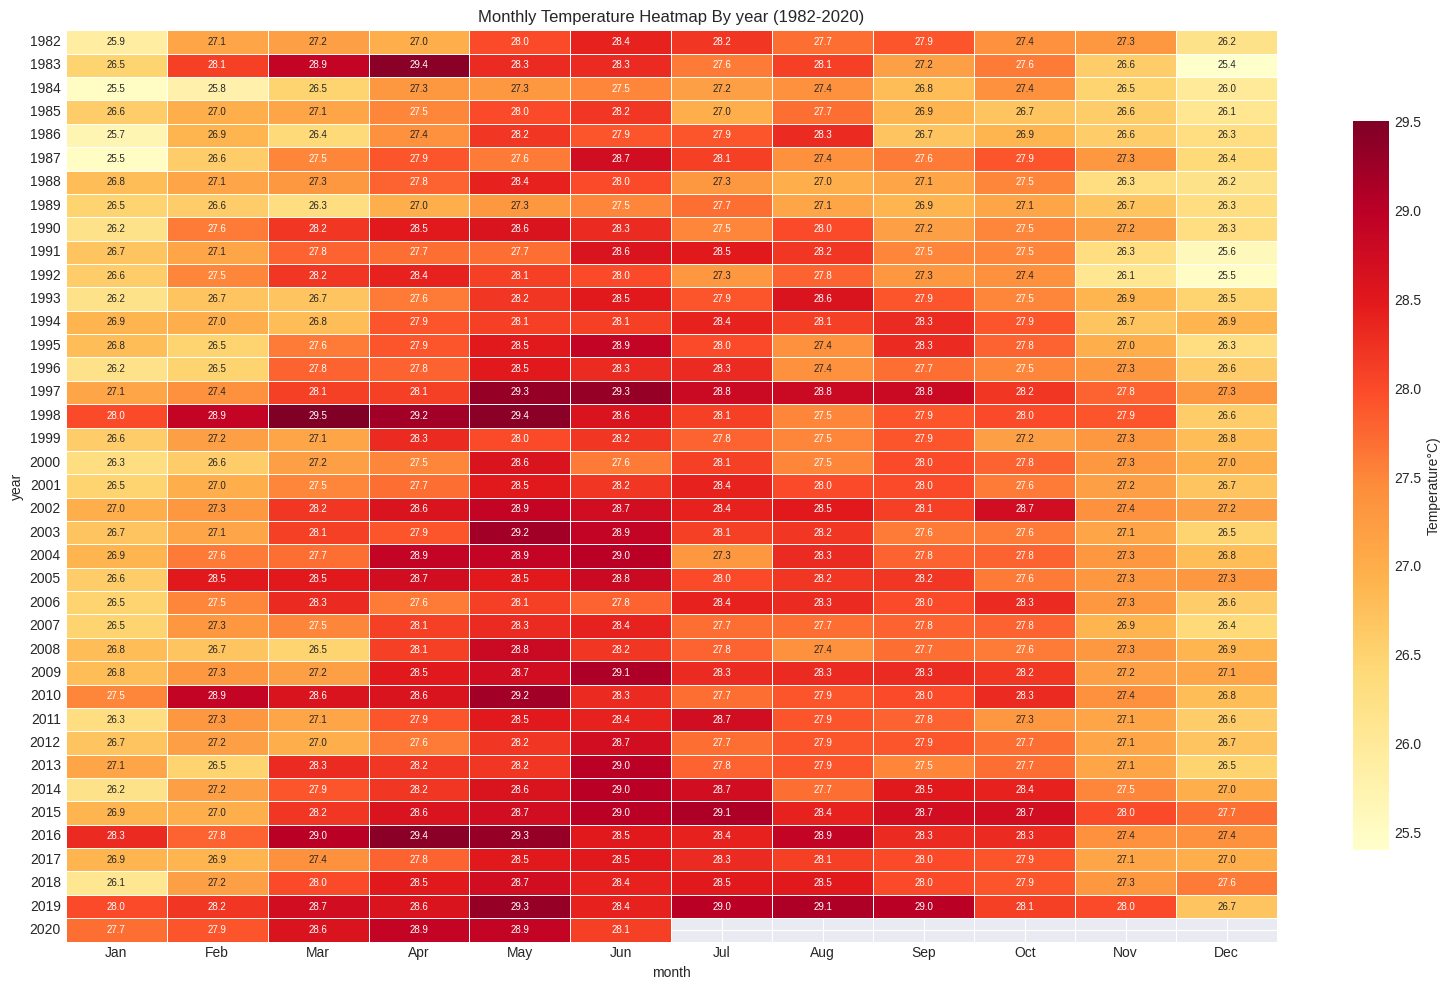

In [ ]:
# Create pivot table using years as rows and month as columns
pivot = series.copy()
pivot_df = pd.DataFrame({
    'year': pivot.index.year,
    'month':pivot.index.month,
    'temp': pivot.values
}).pivot(index = 'year',columns = 'month', values = 'temp')
pivot_df.columns = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
fig, ax = plt.subplots(figsize = (16,10))
sns.heatmap(pivot_df, cmap = 'YlOrRd', annot = True, fmt = '.1f',
            linewidths = 0.4, linecolor = 'white',cbar_kws = {'label': 'Temperature°C)','shrink':0.8},
            ax = ax, annot_kws = {'size':7})
ax.set_title('Monthly Temperature Heatmap By year (1982-2020)')
ax.set_xlabel('month')
ax.set_ylabel('year')
plt.tight_layout()
plt.savefig('EDA_heatmap.png',dpi =150, bbox_inches = 'tight')
plt.show()

**Detect Outliers**

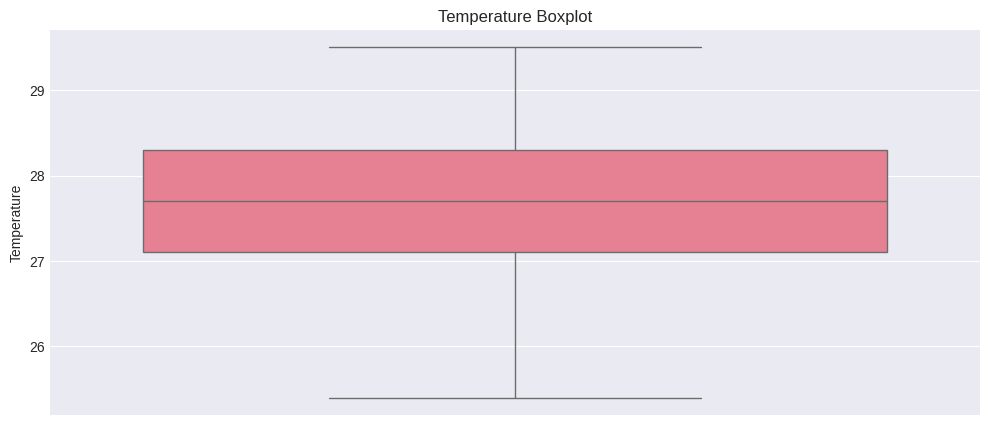

In [ ]:
plt.figure(figsize=(12,5))
sns.boxplot(data['Temperature'])
plt.title('Temperature Boxplot')
plt.show()

Stationarity Checking



*  ARIMA and SARIMA require a stationary series(i.e,mean and variance).
* So, we do two complementary tests to avoid over-relying on single test.



In [ ]:
# Check stationary(ADF)
result = adfuller(data['Temperature'])
print('ADF Statistic:',result[0])
print('p-Value:',result[1])

ADF Statistic: -4.265046395360647
p-Value: 0.0005103681123778804


In [ ]:
def stationarity_report(s, title="Series"):
    adf  = adfuller(s.dropna(), autolag='AIC')
    kpss_result = kpss(s.dropna(), regression='c', nlags='auto')
    print(f"\n{'='*55}")
    print(f"  STATIONARITY TESTS: {title}")
    print(f"{'='*55}")
    print(f"\n ADF Test")
    print(f"  Test Statistic : {adf[0]:.5f}")
    print(f"  p-value        : {adf[1]:.5f}")
    print(f"  Critical Values:")
    for k, v in adf[4].items():
        print(f"    {k:6s}: {v:.4f}")
    conclusion_adf = "STATIONARY (reject H₀)" if adf[1] < 0.05 else "NON-STATIONARY (fail to reject H₀)"
    print(f"  Conclusion     : {conclusion_adf}")
    print(f"\nKPSS Test")
    print(f"  Test Statistic : {kpss_result[0]:.5f}")
    print(f"  p-value        : {kpss_result[1]:.5f}")
    conclusion_kpss = "STATIONARY (fail to reject H₀)" if kpss_result[1] > 0.05 else " NON-STATIONARY (reject H₀)"
    print(f"  Conclusion     : {conclusion_kpss}")
    return adf[1], kpss_result[1]
adf_p, kpss_p = stationarity_report(series, "Original Series")



  STATIONARITY TESTS: Original Series

 ADF Test
  Test Statistic : -4.26505
  p-value        : 0.00051
  Critical Values:
    1%    : -3.4452
    5%    : -2.8681
    10%   : -2.5703
  Conclusion     : STATIONARY (reject H₀)

KPSS Test
  Test Statistic : 1.86596
  p-value        : 0.01000
  Conclusion     :  NON-STATIONARY (reject H₀)


/tmp/ipykernel_6109/3477966035.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(s.dropna(), regression='c', nlags='auto')


**Differencing**

In [ ]:
# First Differencing
series_diff1 = series.diff().dropna()
adf_p1, kpss_p1 = stationarity_report (series_diff1,"First Difference")
# Seasonal Differencing
series_diff2 = series.diff(12).dropna()
adf_p_s, kpss_p_s = stationarity_report(series_diff2,"Seasonal Difference")
# First + Seasonal Differencing
series_diff_both = series.diff(12).diff().dropna()
adf_p_b, kpss_p_b = stationarity_report(series_diff_both,"First + Seasonal Difference")


  STATIONARITY TESTS: First Difference

 ADF Test
  Test Statistic : -5.54412
  p-value        : 0.00000
  Critical Values:
    1%    : -3.4452
    5%    : -2.8681
    10%   : -2.5703
  Conclusion     : STATIONARY (reject H₀)

KPSS Test
  Test Statistic : 0.01428
  p-value        : 0.10000
  Conclusion     : STATIONARY (fail to reject H₀)

  STATIONARITY TESTS: Seasonal Difference

 ADF Test
  Test Statistic : -7.19564
  p-value        : 0.00000
  Critical Values:
    1%    : -3.4454
    5%    : -2.8682
    10%   : -2.5703
  Conclusion     : STATIONARY (reject H₀)

KPSS Test
  Test Statistic : 0.02288
  p-value        : 0.10000
  Conclusion     : STATIONARY (fail to reject H₀)

  STATIONARITY TESTS: First + Seasonal Difference

 ADF Test
  Test Statistic : -8.61789
  p-value        : 0.00000
  Critical Values:
    1%    : -3.4456
    5%    : -2.8683
    10%   : -2.5703
  Conclusion     : STATIONARY (reject H₀)

KPSS Test
  Test Statistic : 0.02644
  p-value        : 0.10000
  Conclusi

/tmp/ipykernel_6109/3477966035.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(s.dropna(), regression='c', nlags='auto')
/tmp/ipykernel_6109/3477966035.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(s.dropna(), regression='c', nlags='auto')
/tmp/ipykernel_6109/3477966035.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(s.dropna(), regression='c', nlags='auto')


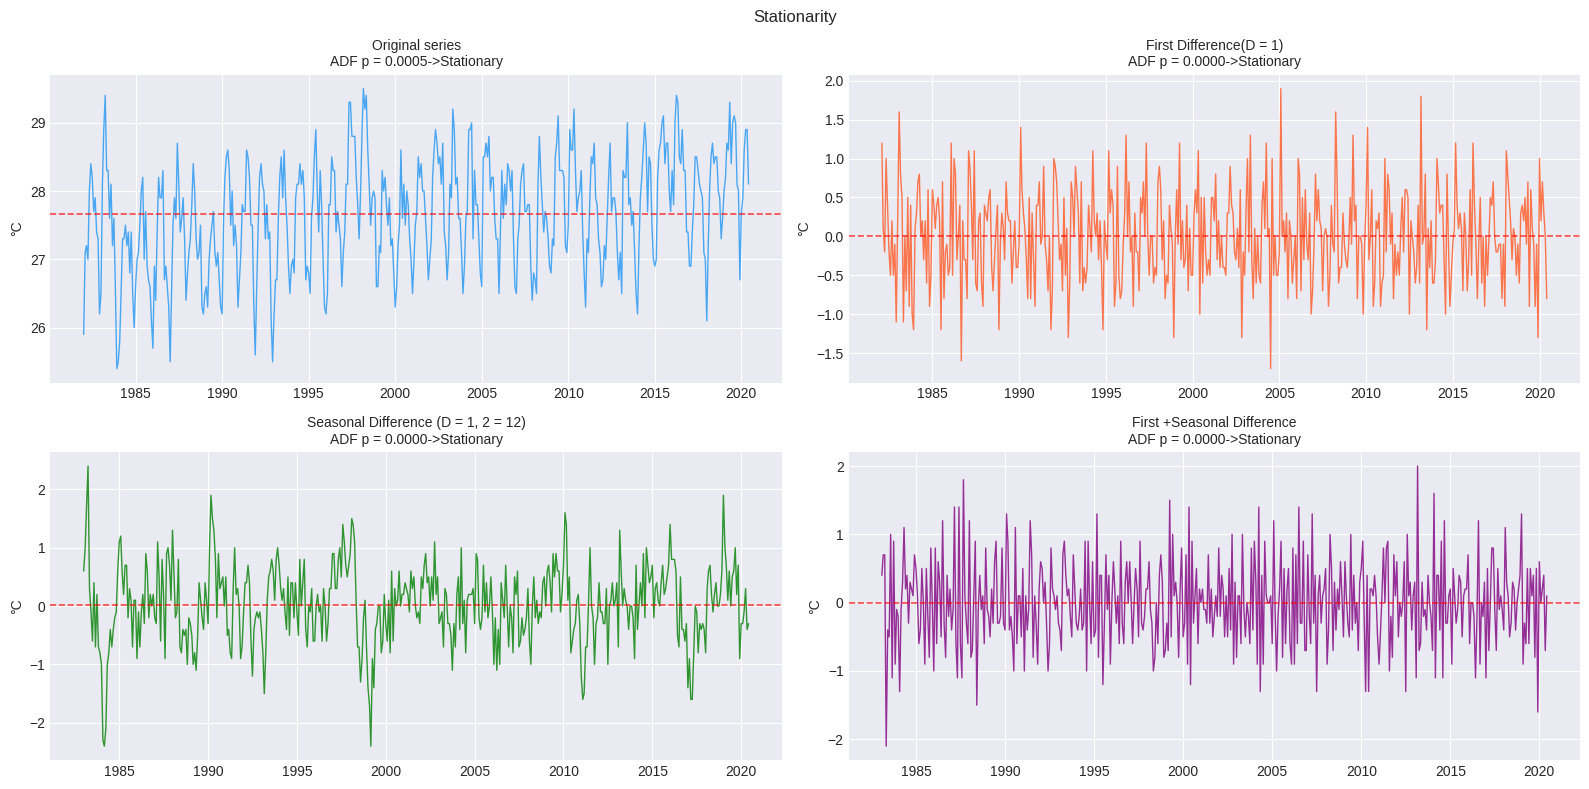

In [ ]:
# Plot for Original and Differenced
fig,axes = plt.subplots(2,2,figsize=(16,8))
fig.suptitle('Stationarity')
pairs = [
    (series, "Original series",COLOR, adf_p),
    (series_diff1, "First Difference(D = 1)",ACCENT, adf_p1),
    (series_diff2, "Seasonal Difference (D = 1, 2 = 12)",'green',adf_p_s),
    (series_diff_both, "First +Seasonal Difference",'purple',adf_p_b),
]
for ax, (s, title,color,p) in zip (axes.flat, pairs):
  ax.plot(s.index, s, color = color,linewidth = 1.0, alpha = 0.8)
  ax.axhline(s.mean(),color = 'red',linestyle='--',linewidth = 1.2, alpha = 0.7)
  status = "Stationary" if p < 0.05 else "Non-Stationary"
  ax.set_title(f"{title}\nADF p = {p:.4f}->{status}",fontsize = 10)
  ax.set_ylabel("°C")
plt.tight_layout()
plt.savefig('Stationarity.png',dpi = 150, bbox_inches = 'tight')
plt.show()

Time Series Decomposition

Here , decompose the series into Trend, Seasonal and Residual components using the classical Additive Decomposition model:

Trend: Long-term detection.
Seasonal: Repeating periodic pattern (period = 12 month)
Residual: Irregular noise after removing trend and seasonality

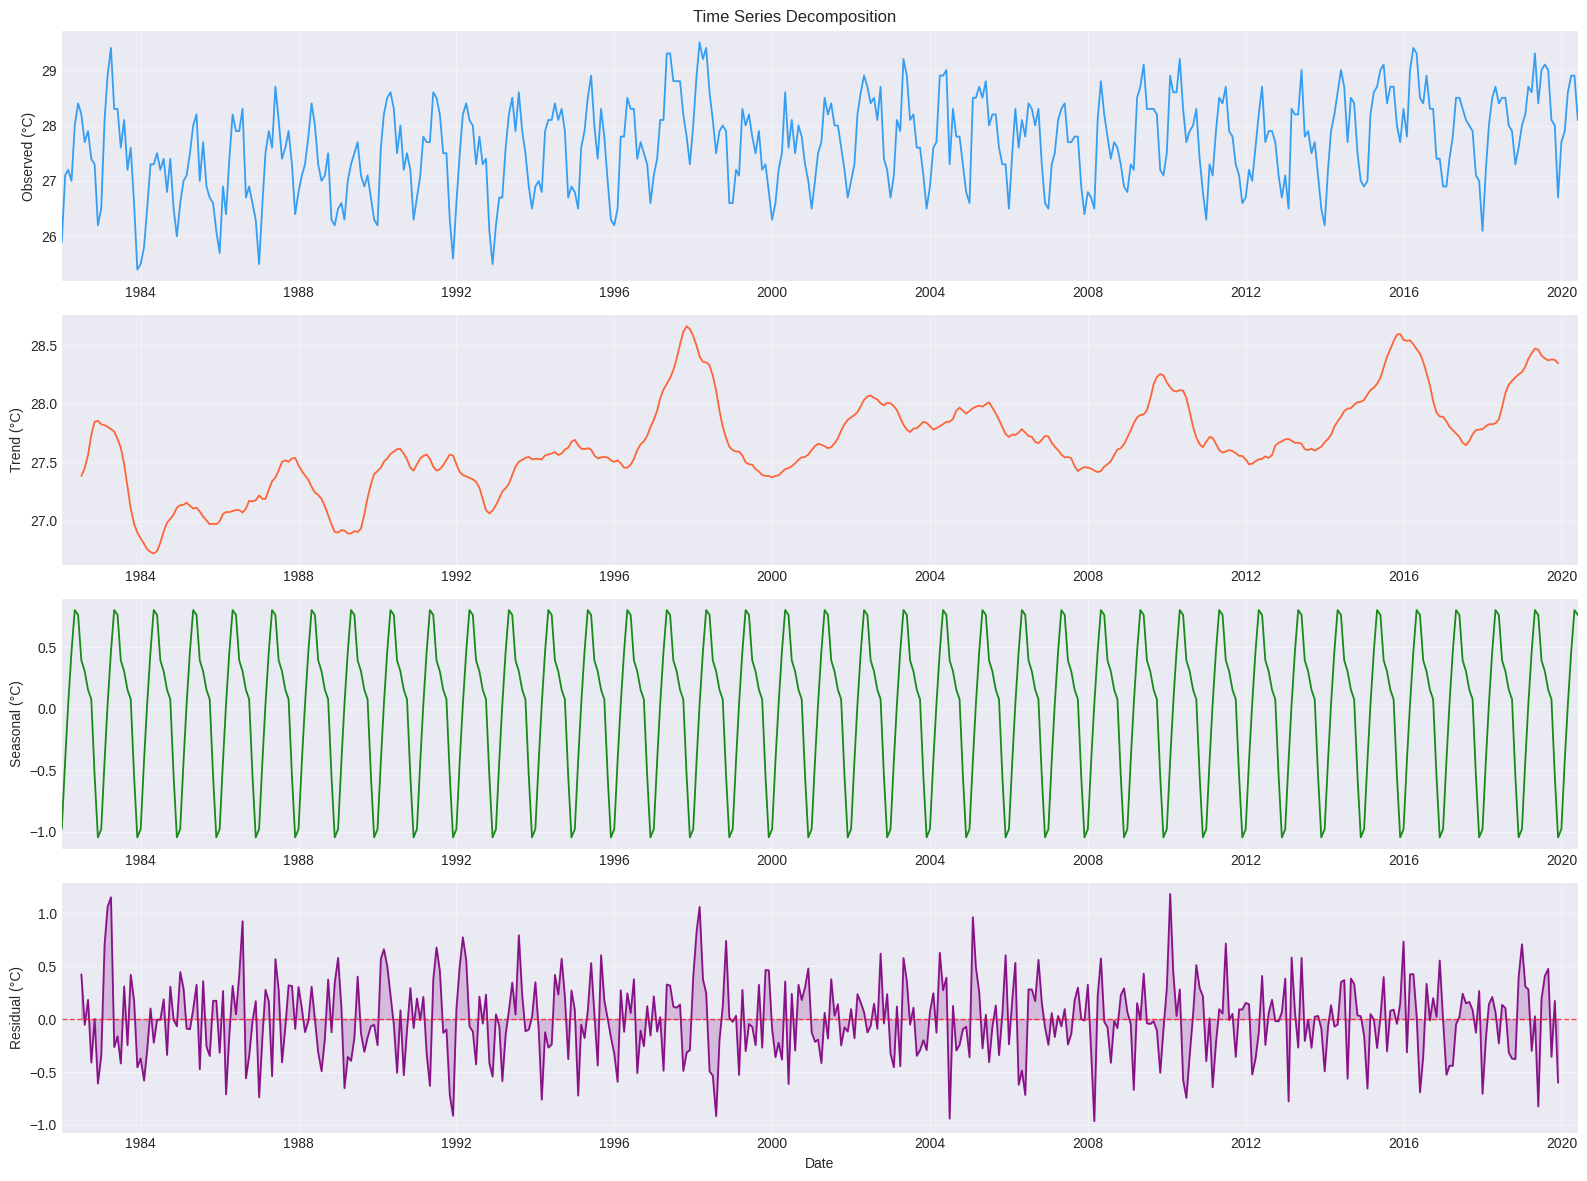

In [ ]:
# Additive Decomposition
decomp = seasonal_decompose(series, model = 'additive',period = 12)
fig,axes = plt.subplots(4,1,figsize = (16,12))
fig.suptitle('Time Series Decomposition')
components = [
    (series, 'Observed',COLOR,'°C'),
    (decomp.trend, 'Trend',ACCENT,'°C'),
    (decomp.seasonal, 'Seasonal','green','°C'),
    (decomp.resid,'Residual','purple','°C'),
]
for ax, (comp, label, color, unit) in zip (axes,components):
  ax.plot(comp.index, comp, color = color, linewidth = 1.3, alpha = 0.9)
  if label == 'Residual':
    ax.axhline(0, color = 'red',linestyle='--',linewidth=1.0,alpha = 0.7)
    ax.fill_between(comp.index,0,comp,alpha=0.2,color=color)
  ax.set_ylabel(f"{label} ({unit})",fontsize = 10)
  ax.set_xlim(series.index[0],series.index[-1])
  ax.grid(True,alpha = 0.4)
axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.savefig('Time Series Decomposition.png',dpi = 150, bbox_inches = 'tight')
plt.show()

In [ ]:
# Seasonal strength metrics
trend_var = decomp.trend.var()
seasonal_var = decomp.seasonal.var()
resid_var = decomp.resid.var()
total_var = series.var()
print("\n Variance Decomposition")
print("-"*50)
print(f"Trend Variance: {trend_var:.4f} ({trend_var/total_var*100:.1f}% of total)")
print(f"Seasonal Variance : {seasonal_var:.4f} ({seasonal_var/total_var*100:.1f}% of total)")
print(f"Residual Variance : {resid_var:.4f} ({resid_var/total_var*100:.1f}% of total)")
# Seasonal strength
Fs = max(0,1 - resid_var/ (resid_var + seasonal_var))
Ft = max(0,1 - resid_var / (resid_var + trend_var))
print(f"Seasonal strength(Fs) : {Fs:4f} {'Strong' if Fs > 0.6 else 'weak'}")
print(f"Trend Strength (Ft) : {Ft:.4f} {'Strong' if Ft >0.6 else 'Weak'}")
# Seasonal Pattern
seasonal_pattern = decomp.seasonal[:12].values
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
print("\n Monthly seasonal effect:")
for m, v in zip(month_names, seasonal_pattern):
  bar = '█'* int(abs(v)*10) if v > 0 else '▒'* int(abs(v)*10)
  sign = '+' if v >0 else '-'
  print(f" {m}:{sign}{abs(v):.3f}°C {bar}")



 Variance Decomposition
--------------------------------------------------
Trend Variance: 0.1538 (23.5% of total)
Seasonal Variance : 0.3558 (54.5% of total)
Residual Variance : 0.1319 (20.2% of total)
Seasonal strength(Fs) : 0.729594 Strong
Trend Strength (Ft) : 0.5383 Weak

 Monthly seasonal effect:
 Jan:-0.978°C ▒▒▒▒▒▒▒▒▒
 Feb:-0.424°C ▒▒▒▒
 Mar:+0.035°C 
 Apr:+0.466°C ████
 May:+0.802°C ████████
 Jun:+0.763°C ███████
 Jul:+0.394°C ███
 Aug:+0.304°C ███
 Sep:+0.154°C █
 Oct:+0.077°C 
 Nov:-0.547°C ▒▒▒▒▒
 Dec:-1.045°C ▒▒▒▒▒▒▒▒▒▒


**ACF & PACF Analysis**

The Autocorrelation Fuction(ACF) and Partial Autocorrelation Function(PACF) helps to identify the orders for ARIMA models.

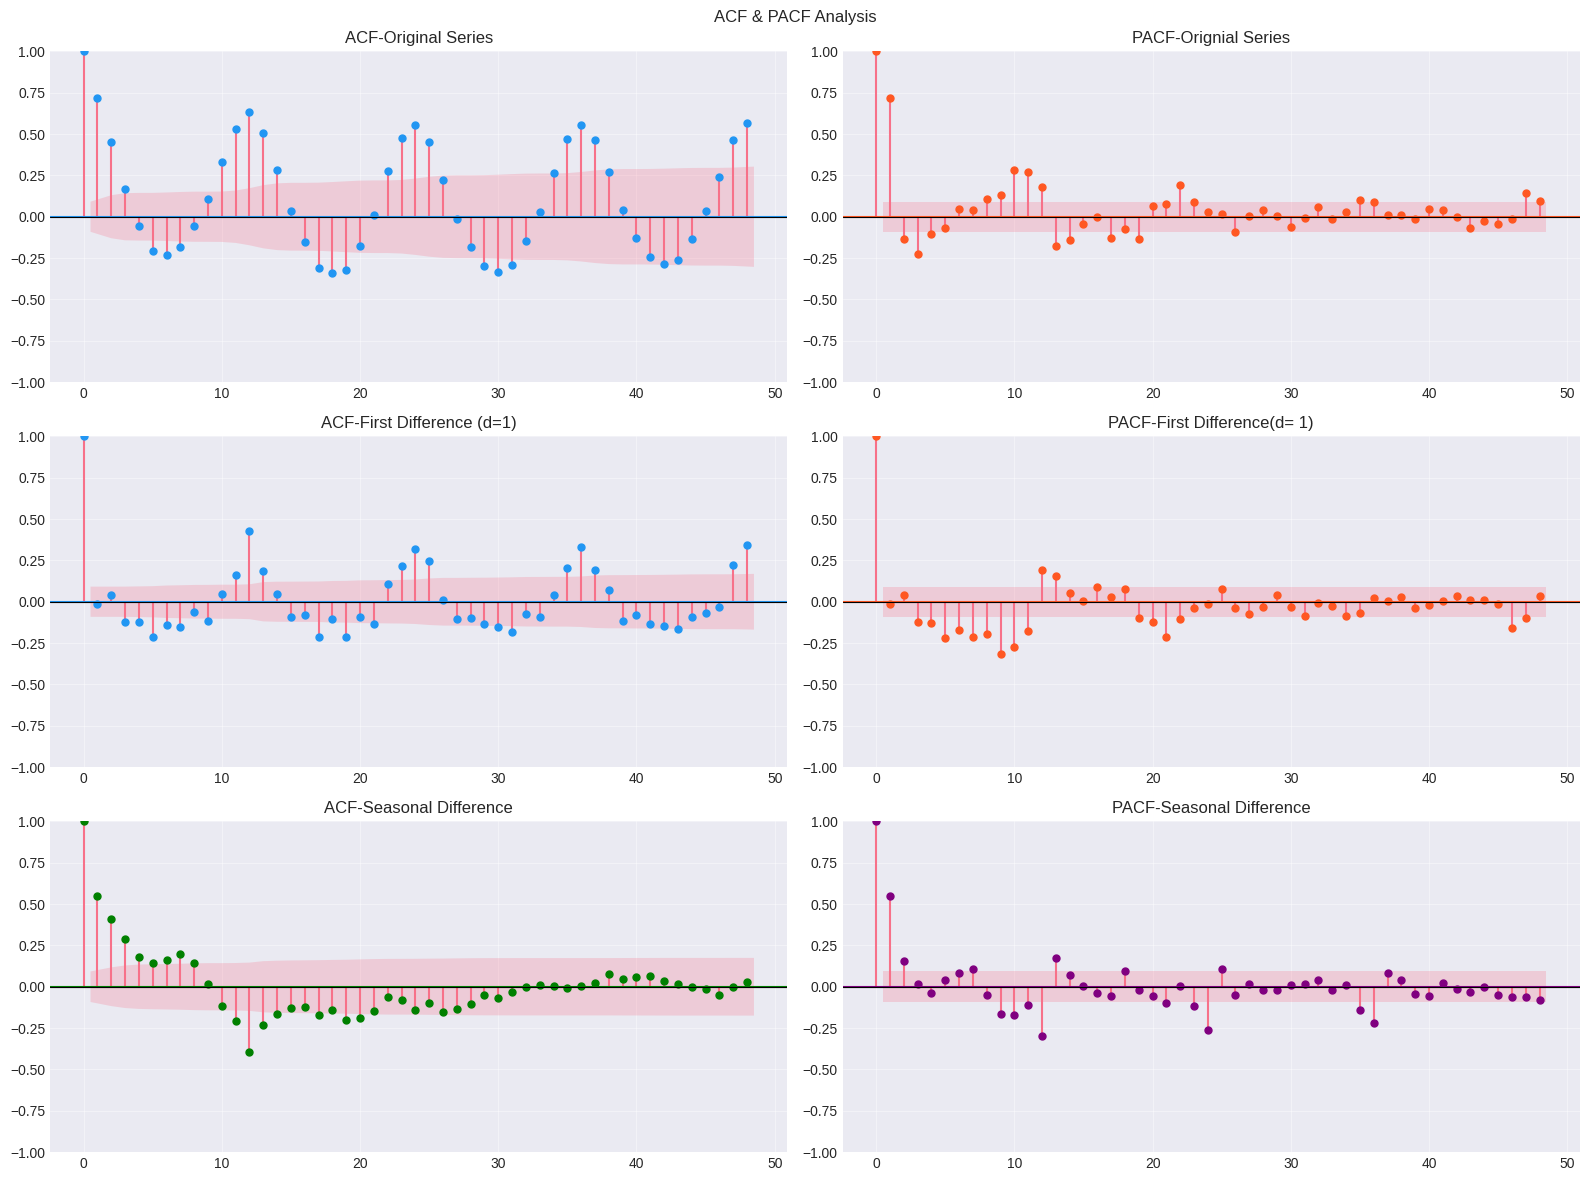

In [ ]:
fig,axes = plt.subplots(3,2,figsize = (16,12))
fig.suptitle('ACF & PACF Analysis')
# Original Series
plot_acf(series, lags=48, ax=axes[0,0], color=COLOR, title ='ACF-Original Series')
plot_pacf(series, lags=48, ax=axes[0,1],color = ACCENT, title = 'PACF-Orignial Series',method = 'ywm')
# First Difference
plot_acf(series_diff1, lags=48,ax=axes[1,0],color=COLOR,title='ACF-First Difference (d=1)')
plot_pacf(series_diff1, lags=48, ax=axes[1,1],color=ACCENT,title='PACF-First Difference(d= 1)',method = 'ywm')
# Seasonal Difference
plot_acf(series_diff2, lags=48,ax=axes[2,0], color = 'green',title="ACF-Seasonal Difference")
plot_pacf(series_diff2, lags=48, ax=axes[2,1], color='purple',title="PACF-Seasonal Difference",method='ywm')
for ax in axes.flat:
  ax.grid(True,alpha = 0.4)
  ax.axhline(0, color = 'black',linewidth=0.8)
plt.tight_layout()
plt.savefig('ACF_PACF.png',dpi=150,bbox_inches='tight')
plt.show()

**Train,Test and Split**

Here,I use a temporal split(never shuffle time series):


*  Train: 1982-2017 (~80% of data, 432 months)
*  Test: 2018-2020 (~14%,30 months)



  Training set : Jan 1982 → Dec 2017  (432 months)
  Test set     : Jan 2018 → Jun 2020  (30 months)


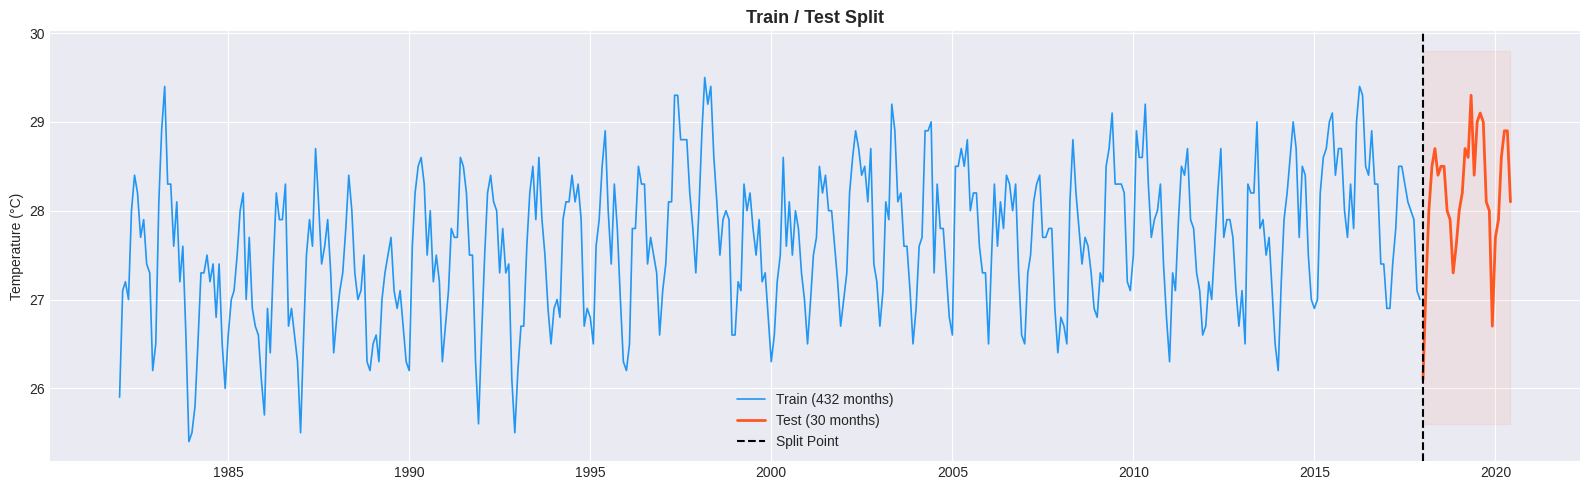

In [ ]:

SPLIT_DATE = '2018-01-01'
train = series[series.index < SPLIT_DATE]
test  = series[series.index >= SPLIT_DATE]
print(f"  Training set : {train.index[0].strftime('%b %Y')} → {train.index[-1].strftime('%b %Y')}  ({len(train)} months)")
print(f"  Test set     : {test.index[0].strftime('%b %Y')} → {test.index[-1].strftime('%b %Y')}  ({len(test)} months)")
# Plot for visualization.
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(train.index, train, color=COLOR,  linewidth=1.2, label=f'Train ({len(train)} months)')
ax.plot(test.index,  test,  color=ACCENT, linewidth=2.0, label=f'Test ({len(test)} months)')
ax.axvline(pd.Timestamp(SPLIT_DATE), color='black', linestyle='--', linewidth=1.5, label='Split Point')
ax.fill_between(test.index, test.min()-0.5, test.max()+0.5, alpha=0.07, color=ACCENT)
ax.set_title("Train / Test Split", fontsize=13, fontweight='bold')
ax.set_ylabel("Temperature (°C)")
ax.legend()
plt.tight_layout()
plt.savefig('Train_Test.png', dpi=150, bbox_inches='tight')
plt.show()


**ARIMA MODEL**

In [ ]:
train.index = pd.DatetimeIndex(train.index, freq='MS')
arima_model = ARIMA(train,order=(1,0,1)).fit()
print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:            Temperature   No. Observations:                  432
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -357.708
Date:                Sun, 20 Sep 2026   AIC                            723.417
Time:                        09:48:38   BIC                            739.691
Sample:                    01-01-1982   HQIC                           729.842
                         - 12-01-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         27.6164      0.088    315.091      0.000      27.445      27.788
ar.L1          0.6602      0.054     12.153      0.000       0.554       0.767
ma.L1          0.1320      0.072      1.838      0.0

  ARIMA(1,0,1) — Test Set Metrics
  MAE  : 0.7862 °C
  RMSE : 0.9043 °C
  R²   : -0.6477
  MAPE : 2.77%


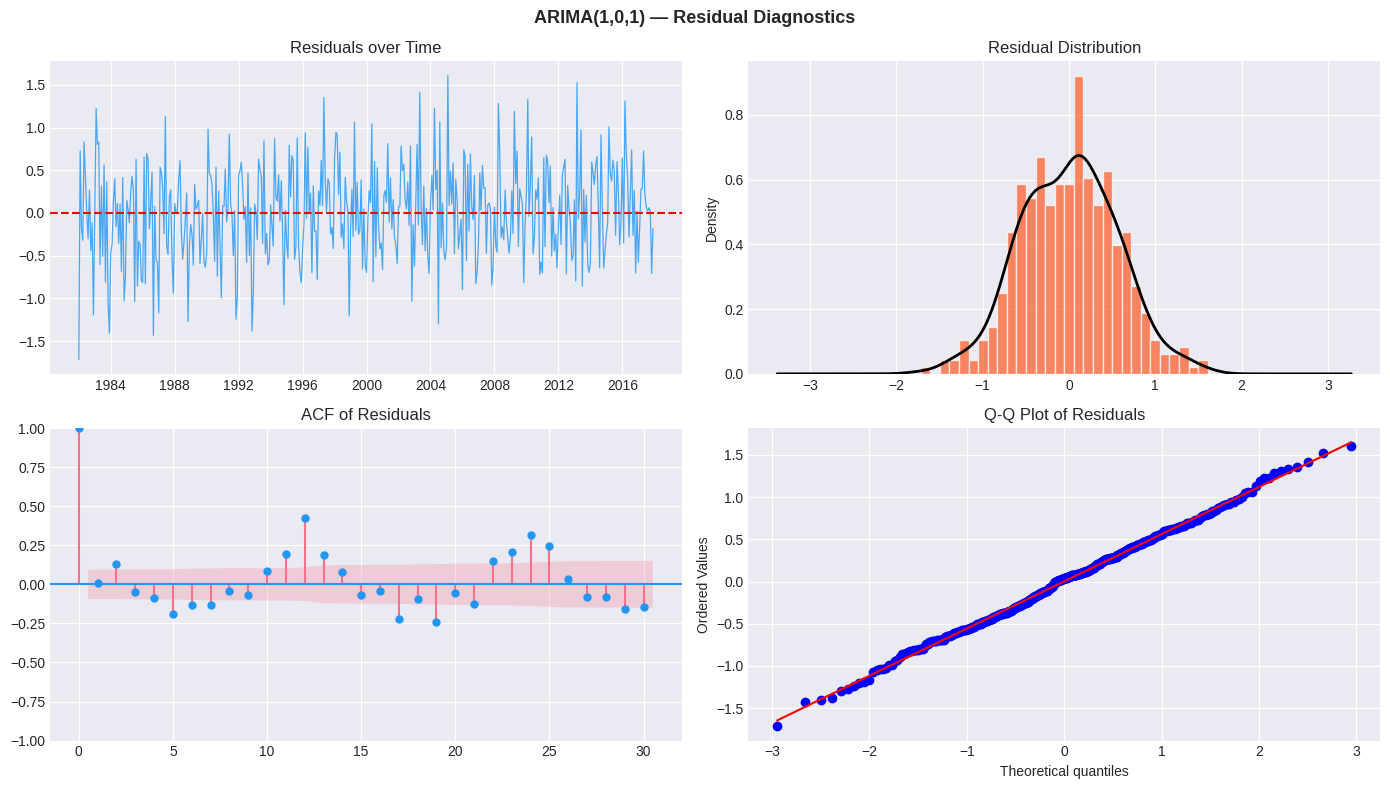

       lb_stat     lb_pvalue
10   48.614354  4.792501e-07
20  220.026683  1.179640e-35


In [ ]:
# ── ARIMA Forecast ───────────────────────────────────────────
arima_forecast = arima_model.get_forecast(steps=len(test))
arima_pred     = arima_forecast.predicted_mean
arima_ci       = arima_forecast.conf_int()
arima_pred.index = test.index
arima_ci.index   = test.index

# ── Metrics ───────────────────────────────────────────────────
arima_mae  = mean_absolute_error(test, arima_pred)
arima_rmse = np.sqrt(mean_squared_error(test, arima_pred))
arima_r2   = r2_score(test, arima_pred)
arima_mape = np.mean(np.abs((test - arima_pred) / test)) * 100

print(f"  ARIMA(1,0,1) — Test Set Metrics")
print(f"  MAE  : {arima_mae:.4f} °C")
print(f"  RMSE : {arima_rmse:.4f} °C")
print(f"  R²   : {arima_r2:.4f}")
print(f"  MAPE : {arima_mape:.2f}%")

# ── Residual diagnostics ──────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("ARIMA(1,0,1) — Residual Diagnostics", fontsize=13, fontweight='bold')

resids = arima_model.resid.dropna()
axes[0,0].plot(resids, color=COLOR, linewidth=0.9, alpha=0.8)
axes[0,0].axhline(0, color='red', linestyle='--')
axes[0,0].set_title("Residuals over Time")
axes[0,1].hist(resids, bins=30, color=ACCENT, alpha=0.7, edgecolor='white', density=True)
resids.plot(kind='kde', ax=axes[0,1], color='black', linewidth=2)
axes[0,1].set_title("Residual Distribution")
plot_acf(resids, lags=30, ax=axes[1,0], title="ACF of Residuals", color=COLOR)
stats.probplot(resids, dist="norm", plot=axes[1,1])
axes[1,1].set_title("Q-Q Plot of Residuals")
plt.tight_layout()
plt.savefig('ARIMA_Diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()
# Ljung-Box test
lb = acorr_ljungbox(resids, lags=[10, 20], return_df=True)
print(lb.to_string())

**SARIMA MODEL**

In [ ]:
! pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 3.8 MB/s eta 0:00:00


In [ ]:
from pmdarima import auto_arima
auto_model = auto_arima(
    train,
    seasonal = True,
    m = 12,
    d = 0, D = 1,
    max_p = 3, max_q = 3,
    max_P = 2, max_Q = 1,
    trend = 't',
    information_criterion = 'aic',
    stepwise = True,
    suppress_warnings = True,
    error_action = 'ignore'
)
print(auto_model.summary())
best_order = auto_model.order
best_seasonal_order = auto_model.seasonal_order
print(f"Best Order: {best_order}")
print(f"Best Seasonal Order: {best_seasonal_order}" )

                                      SARIMAX Results                                       
Dep. Variable:                                    y   No. Observations:                  432
Model:             SARIMAX(2, 0, 2)x(0, 1, [1], 12)   Log Likelihood                -261.864
Date:                              Sun, 20 Sep 2026   AIC                            537.728
Time:                                      09:50:50   BIC                            566.009
Sample:                                  01-01-1982   HQIC                           548.906
                                       - 12-01-2017                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift       1.914e-05   4.83e-05      0.397      0.692   -7.55e-05       0.000
ar.L1          0.57

In [ ]:
# Fit SARIMA Model
model = SARIMAX(
    train,
    order = best_order,
    seasonal_order = best_seasonal_order,
    trend = 't'
)
result = model.fit(disp = False)
print(result.summary())


                                      SARIMAX Results                                       
Dep. Variable:                          Temperature   No. Observations:                  432
Model:             SARIMAX(2, 0, 2)x(0, 1, [1], 12)   Log Likelihood                -261.864
Date:                              Sun, 20 Sep 2026   AIC                            537.728
Time:                                      09:50:58   BIC                            566.009
Sample:                                  01-01-1982   HQIC                           548.906
                                       - 12-01-2017                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift       1.914e-05   4.83e-05      0.397      0.692   -7.55e-05       0.000
ar.L1          0.57

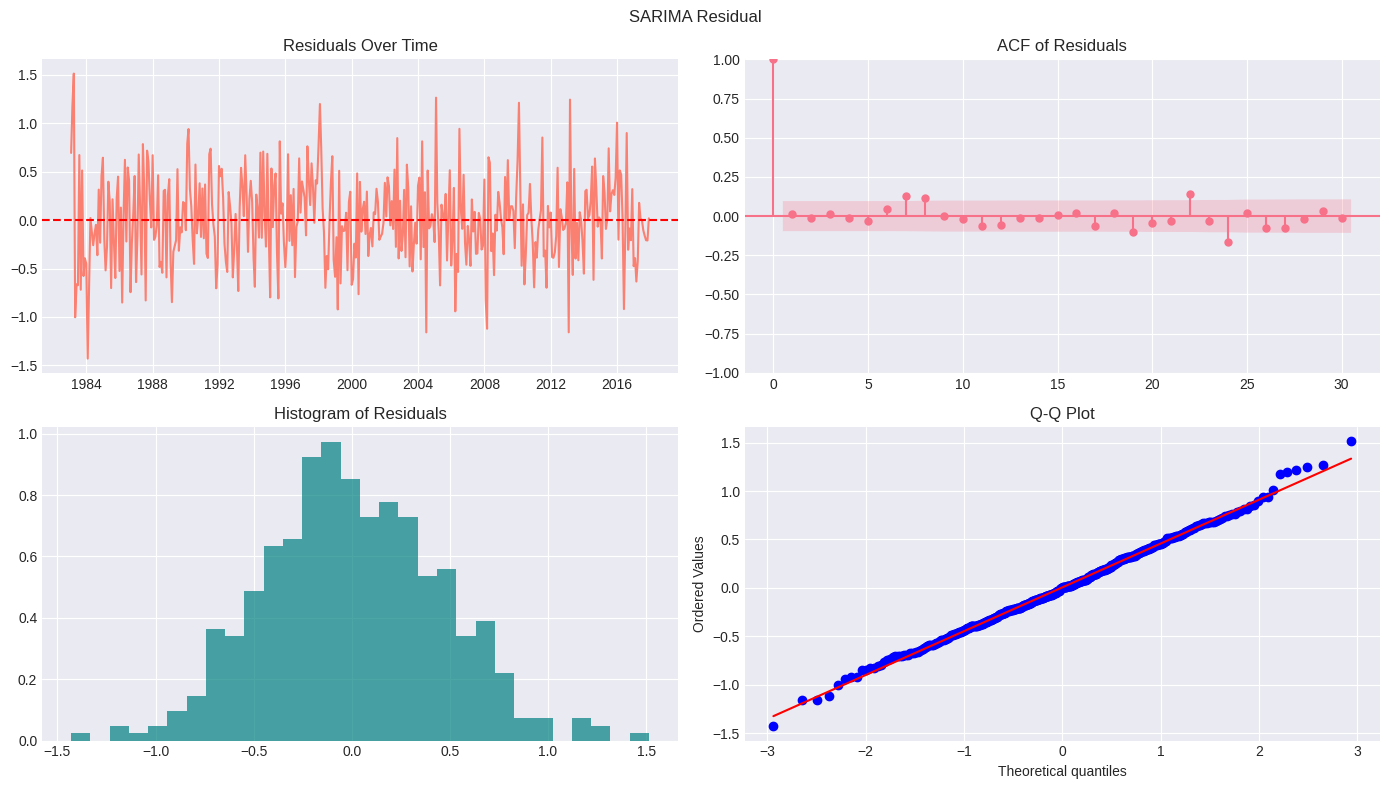

LjungBox Test
      lb_stat  lb_pvalue
10  14.409653   0.155113
20  25.308267   0.189891
All p > 0.05?: True


In [ ]:
# Residual Plots
residuals = result.resid[13:] # Skipping the first 13 intilization artifact
fig,axes = plt.subplots(2,2,figsize = (14,8))
fig.suptitle('SARIMA Residual')
# Residuals over time
axes[0,0].plot(residuals,color = 'salmon')
axes[0,0].axhline(0,color = 'red',linestyle ='--')
axes[0,0].set_title('Residuals Over Time')
# ACF Plot
plot_acf(residuals, lags = 30, ax = axes[0,1])
axes[0,1].set_title('ACF of Residuals')
# Histograms
axes[1,0].hist(residuals, bins=30, density = True, color='teal',alpha = 0.7)
axes[1,0].set_title('Histogram of Residuals')
#Q-Q Plot
stats.probplot(residuals,plot = axes[1,1])
axes[1,1].set_title('Q-Q Plot')
plt.tight_layout()
plt.show()
# Ljungbox test at multiple lags
lb = acorr_ljungbox(residuals,lags = [10,20],return_df = True)
print(f"LjungBox Test")
print(lb)
print("All p > 0.05?:",(lb['lb_pvalue']>0.05).all())

Test Set Metrics
MAE : 0.4085°C
RMSE : 0.4911°C
MAPE : 1.4523%
R² : 0.5141


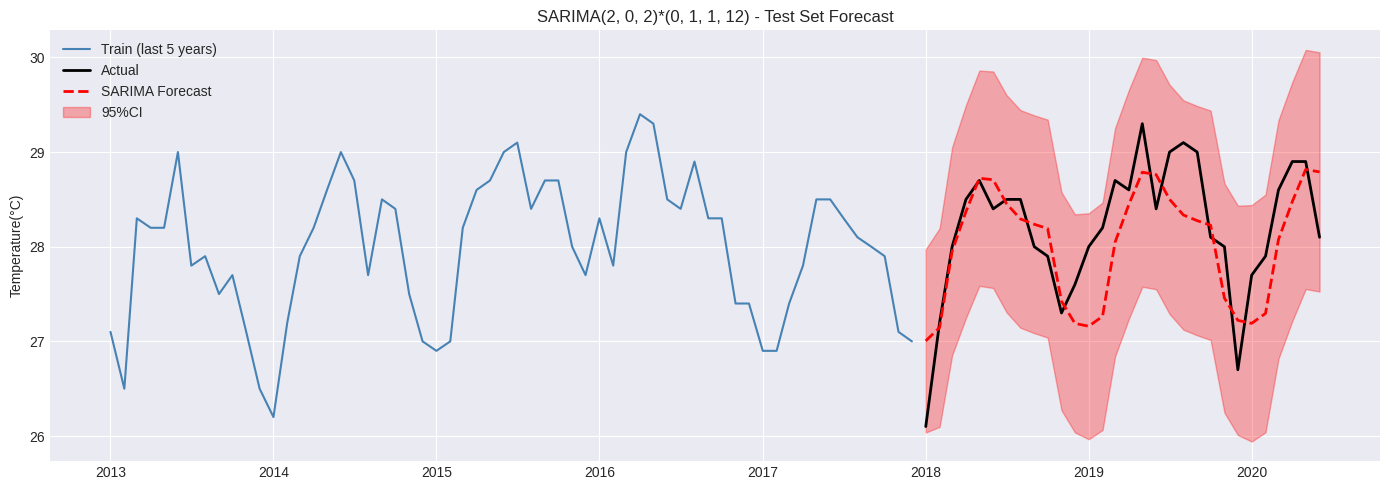

In [ ]:
# Forecast
forecast_obj = result.get_forecast(steps=len(test))
forecast_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int()
# Metrics
mae = np.mean(np.abs(test.values - forecast_mean.values))
rmse = np.sqrt(np.mean((test.values - forecast_mean.values)**2))
mape = np.mean(np.abs((test.values - forecast_mean.values) / test.values))*100
ss_res = np.sum((test.values - forecast_mean.values)**2)
ss_tot = np.sum((test.values - np.mean(test.values))**2)
r2 = 1 - ss_res / ss_tot
print(f"Test Set Metrics")
print(f"MAE : {mae:.4f}°C")
print(f"RMSE : {rmse:.4f}°C")
print(f"MAPE : {mape:.4f}%")
print(f"R² : {r2:.4f}")
# Plot forecast Vs Actual
plt.figure(figsize=(14,5))
plt.plot(train[-60:],label = 'Train (last 5 years)',color = 'steelblue')
plt.plot(test, label = 'Actual',color='black',linewidth=2)
plt.plot(forecast_mean, label = 'SARIMA Forecast',color='red',linestyle='--',linewidth=2)
plt.fill_between(conf_int.index,
                 conf_int.iloc[:,0],
                 conf_int.iloc[:,1],
                 alpha = 0.3,color = 'red',label = '95%CI')
plt.title(f'SARIMA{best_order}*{best_seasonal_order} - Test Set Forecast')
plt.ylabel('Temperature(°C)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
lb = acorr_ljungbox(residuals, lags=[10, 20], return_df=True)
print(lb.to_string())
print("\n Ljung-Box Verdict:")
if (lb['lb_pvalue'] > 0.05).all():
    print("  PASS.Model is well-specified.")
else:
    print("  FAIL.Model may be misspecified.")


      lb_stat  lb_pvalue
10  14.409653   0.155113
20  25.308267   0.189891

 Ljung-Box Verdict:
  PASS.Model is well-specified.


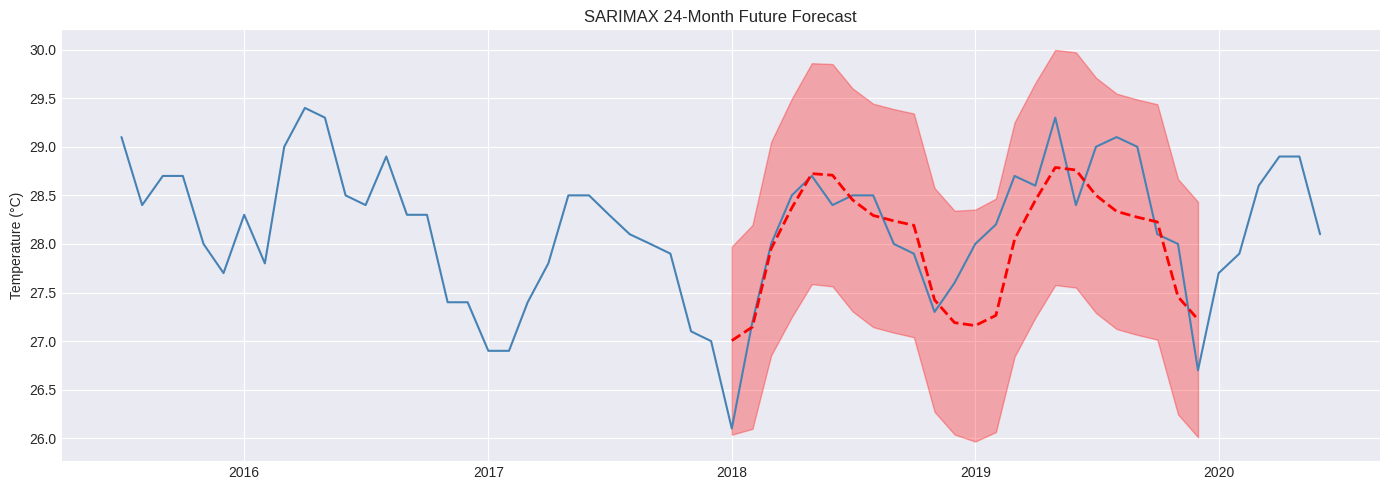

            Forecast  Lower 95%  Upper 95%
2018-01-01    27.005     26.037     27.973
2018-02-01    27.146     26.097     28.195
2018-03-01    27.952     26.853     29.051
2018-04-01    28.371     27.247     29.495
2018-05-01    28.724     27.587     29.861
2018-06-01    28.708     27.564     29.852
2018-07-01    28.454     27.306     29.602
2018-08-01    28.294     27.144     29.443
2018-09-01    28.237     27.087     29.388
2018-10-01    28.192     27.040     29.343
2018-11-01    27.424     26.272     28.575
2018-12-01    27.190     26.038     28.342
2019-01-01    27.160     25.966     28.353
2019-02-01    27.265     26.064     28.466
2019-03-01    28.046     26.840     29.253
2019-04-01    28.448     27.239     29.656
2019-05-01    28.787     27.577     29.997
2019-06-01    28.761     27.551     29.972
2019-07-01    28.501     27.290     29.712
2019-08-01    28.335     27.124     29.547
2019-09-01    28.275     27.064     29.487
2019-10-01    28.227     27.015     29.438
2019-11-01 

In [ ]:
# 24-Month Air Temperature Forecast
future = result.get_forecast(steps = 24)
future_mean = future.predicted_mean
future_ci = future.conf_int()
# Visualization plot
plt.figure(figsize = (14,5))
plt.plot(data['Temperature'][-60:],label = 'Last 5 years',color = 'steelblue')
plt.plot(future_mean, label = '24-month Forecast',color = 'red',linestyle = '--',linewidth=2)
plt.fill_between(future_ci.index,future_ci.iloc[:,0],future_ci.iloc[:,1],alpha = 0.3,color = 'red',label = '95% CI')
plt.title('SARIMAX 24-Month Future Forecast')
plt.ylabel('Temperature (°C)')
plt.tight_layout()
plt.show()
# Print forecast table
print(pd.DataFrame({
    'Forecast': future_mean.round(3),
    'Lower 95%': future_ci.iloc[:,0].round(3),
    'Upper 95%': future_ci.iloc[:,1].round(3)
}))

**Model Summary The SARIMAX model** was fitted on the complete dataset (1982-2020) and used to generate a 24-month forecast(2018-2019) with 95% confidence intervals.

Feature Engineering for Machine Learning

In [ ]:
# Feature Engineering
def create_features(series, n_lags=12):
  data = pd.DataFrame({'Temperature':series})
  for i in range(1, n_lags +1):
    data[f'lag_{i}'] = data['Temperature'].shift(i)
  # Rolling Statistics
  data['rolling_mean_3'] = data['Temperature'].shift(1).rolling(3).mean()
  data['rolling_mean_6'] = data['Temperature'].shift(1).rolling(6).mean()
  data['rolling_mean_12'] = data['Temperature'].shift(1).rolling(12).mean()
  data['rolling_std_3'] = data['Temperature'].shift(1).rolling(3).std()
  data['rolling_std_6'] = data['Temperature'].shift(1).rolling(6).std()
  # Time-Based Features
  data['month'] = series.index.month
  data['year'] = series.index.year
  data['quarter'] = series.index.quarter
  data['month_sin'] = np.sin(2 * np.pi * series.index.month / 12)
  data['month_cos'] = np.cos(2 * np.pi * series.index.month / 12)
  # Drop NaN rows created by lagging
  data.dropna(inplace = True)
  return data

# Create futured dataset
data_featured = create_features(data['Temperature'],n_lags=12)
# Define the features and target
feature_cols = [col for col in data_featured.columns if col != 'Temperature']
X = data_featured[feature_cols]
y = data_featured['Temperature']
print(f"Feature matrix Shape : {X.shape}")
print(f"Target shape : {y.shape}")
print(f"Features used : {feature_cols}")

Feature matrix Shape : (450, 22)
Target shape : (450,)
Features used : ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_8', 'lag_9', 'lag_10', 'lag_11', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_3', 'rolling_std_6', 'month', 'year', 'quarter', 'month_sin', 'month_cos']


**Train,Test and Split**

In [ ]:
split_date = '2017-12-31'
X_train = X[X.index <= split_date]
X_test = X[X.index > split_date]
y_train = y[y.index <= split_date]
y_test = y[y.index > split_date]
print(f"\nTrain Size : {len(X_train)}")
print(f"Test Size : {len(X_test)}")



Train Size : 420
Test Size : 30


In [ ]:
# Scaling
from sklearn.preprocessing import MinMaxScaler
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel()

In [ ]:
def prepare_lstm_data(X_scaled,y_scaled):
  X_lstm = X_scaled.reshape((X_scaled.shape[0],1,X_scaled.shape[1]))
  return X_lstm, y_scaled
X_train_lstm, y_train_lstm = prepare_lstm_data(X_train_scaled, y_train_scaled)
X_test_lstm, y_test_lstm = prepare_lstm_data(X_test_scaled,y_test_scaled)

In [ ]:
# Model Building
def build_lstm(input_shape):
  model = Sequential([
      LSTM(64,activation = 'relu',
           input_shape = input_shape,
           return_sequences = True),
      Dropout(0.2),
      LSTM(32,activation = 'relu'),
      Dropout(0.2),
      Dense(1)
  ])
  model.compile(optimizer = 'adam',loss = 'mse')
  return model

In [ ]:
def prepare_sequence_lstm(series, n_steps=12):
    X, y = [], []
    for i in range(n_steps, len(series)):
        X.append(series[i-n_steps:i])
        y.append(series[i])
    return np.array(X), np.array(y)

# Scale the raw series
scaler_lstm = MinMaxScaler()
series_scaled = scaler_lstm.fit_transform(
    data['Temperature'].values.reshape(-1,1)).ravel()

# Split index
split_idx = data.index.get_loc('2018-01-01')

X_lstm_all, y_lstm_all = prepare_sequence_lstm(series_scaled, n_steps=12)

X_train_lstm = X_lstm_all[:split_idx-12].reshape(-1, 12, 1)
y_train_lstm = y_lstm_all[:split_idx-12]
X_test_lstm  = X_lstm_all[split_idx-12:].reshape(-1, 12, 1)
y_test_lstm  = y_lstm_all[split_idx-12:]

# Build proper sequence LSTM
lstm_seq = Sequential([
    LSTM(64, return_sequences=True, input_shape=(12, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])
lstm_seq.compile(optimizer='adam', loss='mse')
lstm_seq.fit(X_train_lstm, y_train_lstm,
             epochs=100, batch_size=16,
             validation_split=0.1,
             callbacks=[EarlyStopping(patience=10,
                        restore_best_weights=True)],
             verbose=0)

# Predict and inverse transform
lstm_seq_pred = scaler_lstm.inverse_transform(
    lstm_seq.predict(X_test_lstm)).ravel()

# Align with test index
lstm_seq_series = pd.Series(lstm_seq_pred,
                            index=test.index[:len(lstm_seq_pred)])
print("Sequence LSTM MAE:",
      mean_absolute_error(test.values[:len(lstm_seq_pred)],
                          lstm_seq_pred))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
Sequence LSTM MAE: 0.3669734700520832


In [ ]:
# Create results dictionary for baseline LSTM

results = {
    'LSTM': {
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    }
}

print(results)

{'LSTM': {'MAE': np.float64(0.40848685350699143), 'RMSE': np.float64(0.4910937572458152), 'R2': np.float64(0.5140796289031977)}}


In [ ]:
# ============================================
# Baseline LSTM vs Improved Sequence LSTM
# ============================================

# Baseline LSTM metrics
baseline_lstm_mae  = results['LSTM']['MAE']
baseline_lstm_rmse = results['LSTM']['RMSE']
baseline_lstm_r2   = results['LSTM']['R2']


# Improved Sequence LSTM metrics
seq_lstm_mae = mean_absolute_error(
    y_test.values,
    lstm_seq_pred
)

seq_lstm_rmse = np.sqrt(mean_squared_error(
    y_test.values,
    lstm_seq_pred
))

seq_lstm_r2 = r2_score(
    y_test.values,
    lstm_seq_pred
)


# Improvement %
mae_improvement = (
    (baseline_lstm_mae - seq_lstm_mae)
    / baseline_lstm_mae
) * 100

rmse_improvement = (
    (baseline_lstm_rmse - seq_lstm_rmse)
    / baseline_lstm_rmse
) * 100

r2_improvement = (
    (seq_lstm_r2 - baseline_lstm_r2)
    / abs(baseline_lstm_r2)
) * 100


# ============================================
# Print Comparison
# ============================================

print("=" * 60)
print("   LSTM — Baseline vs Improved Sequence Comparison")
print("=" * 60)

print(
    f"{'Metric':<10}"
    f"{'Baseline (1-step)':>20}"
    f"{'Improved (12-step)':>22}"
)

print("-" * 60)

print(
    f"{'MAE':<10}"
    f"{baseline_lstm_mae:>20.4f}"
    f"{seq_lstm_mae:>22.4f}"
)

print(
    f"{'RMSE':<10}"
    f"{baseline_lstm_rmse:>20.4f}"
    f"{seq_lstm_rmse:>22.4f}"
)

print(
    f"{'R²':<10}"
    f"{baseline_lstm_r2:>20.4f}"
    f"{seq_lstm_r2:>22.4f}"
)

print("=" * 60)

print(f"\nMAE  improvement : {mae_improvement:+.2f}%")
print(f"RMSE improvement : {rmse_improvement:+.2f}%")
print(f"R²   improvement : {r2_improvement:+.2f}%")

   LSTM — Baseline vs Improved Sequence Comparison
Metric       Baseline (1-step)    Improved (12-step)
------------------------------------------------------------
MAE                     0.4085                0.3670
RMSE                    0.4911                0.4602
R²                      0.5141                0.5733

MAE  improvement : +10.16%
RMSE improvement : +6.29%
R²   improvement : +11.51%


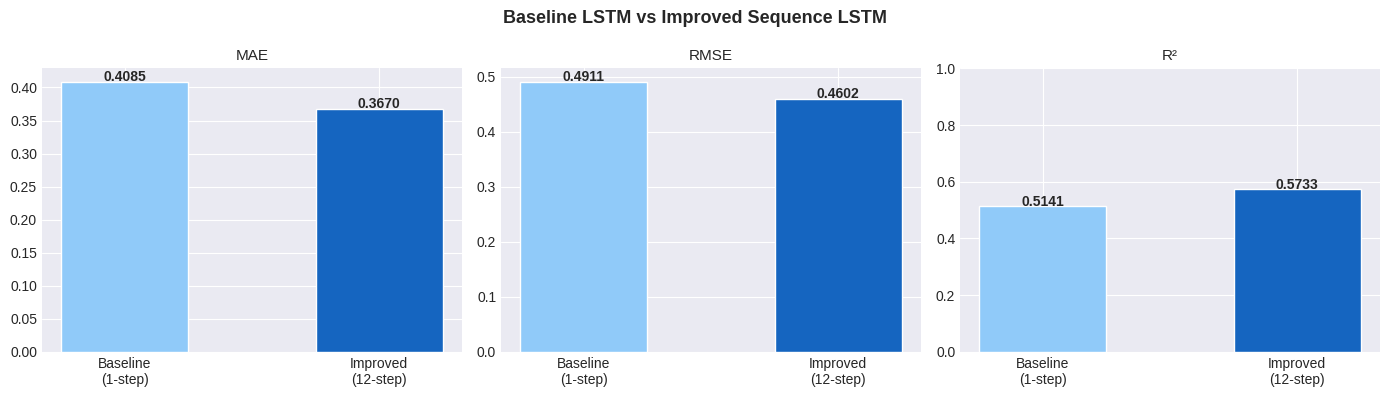

In [ ]:
# ============================================
# Visual Comparison
# ============================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

fig.suptitle(
    'Baseline LSTM vs Improved Sequence LSTM',
    fontweight='bold',
    fontsize=13
)

metrics = ['MAE', 'RMSE', 'R²']

baseline = [
    baseline_lstm_mae,
    baseline_lstm_rmse,
    baseline_lstm_r2
]

improved = [
    seq_lstm_mae,
    seq_lstm_rmse,
    seq_lstm_r2
]

for ax, metric, b_val, i_val in zip(
    axes, metrics, baseline, improved
):

    bars = ax.bar(
        ['Baseline\n(1-step)', 'Improved\n(12-step)'],
        [b_val, i_val],
        color=['#90CAF9', '#1565C0'],
        edgecolor='white',
        width=0.5
    )

    ax.set_title(metric, fontsize=11)

    for bar, val in zip(bars, [b_val, i_val]):

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.002,
            f'{val:.4f}',
            ha='center',
            fontsize=10,
            fontweight='bold'
        )

    if metric == 'R²':
        ax.set_ylim(0, 1)

plt.tight_layout()

plt.savefig(
    'lstm_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

In [ ]:
models = {
    'Linear Regression':LinearRegression(),
    'Decision Tree':DecisionTreeRegressor(),
    'Random Forest': RandomForestRegressor(n_estimators=200,max_depth=10,random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200,learning_rate=0.05,max_depth=5,random_state=42),
    'KNN':KNeighborsRegressor(n_neighbors=5),
    'XGBoost':XGBRegressor(n_estimators = 200,learning_rate = 0.05,max_depth =5,random_state = 42,verbosity = 0),
    'SVM':SVR(kernel = 'rbf',C = 100,epsilon = 0.1),
    'LSTM':'lstm'
}


In [ ]:
def evaluate_model(y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2   = r2_score(y_true, y_pred)
    return {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}
# Store results and predictions
results     = {}
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    if name == 'LSTM':
        # Build and train LSTM
        lstm_model = build_lstm((X_train_lstm.shape[1],
                                 X_train_lstm.shape[2]))
        early_stop = EarlyStopping(monitor='val_loss',
                                   patience=10,
                                   restore_best_weights=True)
        lstm_model.fit(
            X_train_lstm, y_train_lstm,
            epochs=100,
            batch_size=16,
            validation_split=0.1,
            callbacks=[early_stop],
            verbose=0
        )
        # Predict and inverse transform
        y_pred_scaled = lstm_model.predict(X_test_lstm, verbose=0).ravel()
        y_pred = scaler_y.inverse_transform(
                     y_pred_scaled.reshape(-1, 1)).ravel()

    else:
        # Train standard ML models
        model.fit(X_train_scaled, y_train_scaled)
        y_pred_scaled = model.predict(X_test_scaled)
        y_pred = scaler_y.inverse_transform(
                     y_pred_scaled.reshape(-1, 1)).ravel()

    # Store predictions and metrics
    predictions[name] = y_pred
    results[name]     = evaluate_model(y_test.values, y_pred)
    print(f"  MAE  : {results[name]['MAE']:.4f}°C")
    print(f"  RMSE : {results[name]['RMSE']:.4f}°C")
    print(f"  MAPE : {results[name]['MAPE']:.4f}%")
    print(f"  R²   : {results[name]['R2']:.4f}")


Training Linear Regression...
  MAE  : 0.3271°C
  RMSE : 0.4104°C
  MAPE : 1.1733%
  R²   : 0.6606

Training Decision Tree...
  MAE  : 0.4100°C
  RMSE : 0.5070°C
  MAPE : 1.4563%
  R²   : 0.4822

Training Random Forest...
  MAE  : 0.3508°C
  RMSE : 0.4206°C
  MAPE : 1.2508%
  R²   : 0.6436

Training Gradient Boosting...
  MAE  : 0.3457°C
  RMSE : 0.4315°C
  MAPE : 1.2335%
  R²   : 0.6248

Training KNN...
  MAE  : 0.4013°C
  RMSE : 0.4711°C
  MAPE : 1.4271%
  R²   : 0.5529

Training XGBoost...
  MAE  : 0.3767°C
  RMSE : 0.4582°C
  MAPE : 1.3445%
  R²   : 0.5769

Training SVM...
  MAE  : 0.3936°C
  RMSE : 0.4953°C
  MAPE : 1.4070%
  R²   : 0.5058

Training LSTM...
  MAE  : 0.4590°C
  RMSE : 0.5544°C
  MAPE : 1.6287%
  R²   : 0.3808


In [ ]:
results['SARIMA'] = evaluate_model(test.values, forecast_mean.values)
results_df = pd.DataFrame(results).T
results_df = results_df.round(4)
results_df.index.name = 'Model'
print(results_df.to_string())
print('\nBest MAE:',results_df['MAE'].idxmin())
print('Best RMSE:',results_df['RMSE'].idxmin())
print('Best MAPE:',results_df['MAPE'].idxmin())
print('Best R2:',results_df['R2'].idxmax())


                      MAE    RMSE    MAPE      R2
Model                                            
Linear Regression  0.3271  0.4104  1.1733  0.6606
Decision Tree      0.4100  0.5070  1.4563  0.4822
Random Forest      0.3508  0.4206  1.2508  0.6436
Gradient Boosting  0.3457  0.4315  1.2335  0.6248
KNN                0.4013  0.4711  1.4271  0.5529
XGBoost            0.3767  0.4582  1.3445  0.5769
SVM                0.3936  0.4953  1.4070  0.5058
LSTM               0.4590  0.5544  1.6287  0.3808
SARIMA             0.4085  0.4911  1.4523  0.5141

Best MAE: Linear Regression
Best RMSE: Linear Regression
Best MAPE: Linear Regression
Best R2: Linear Regression


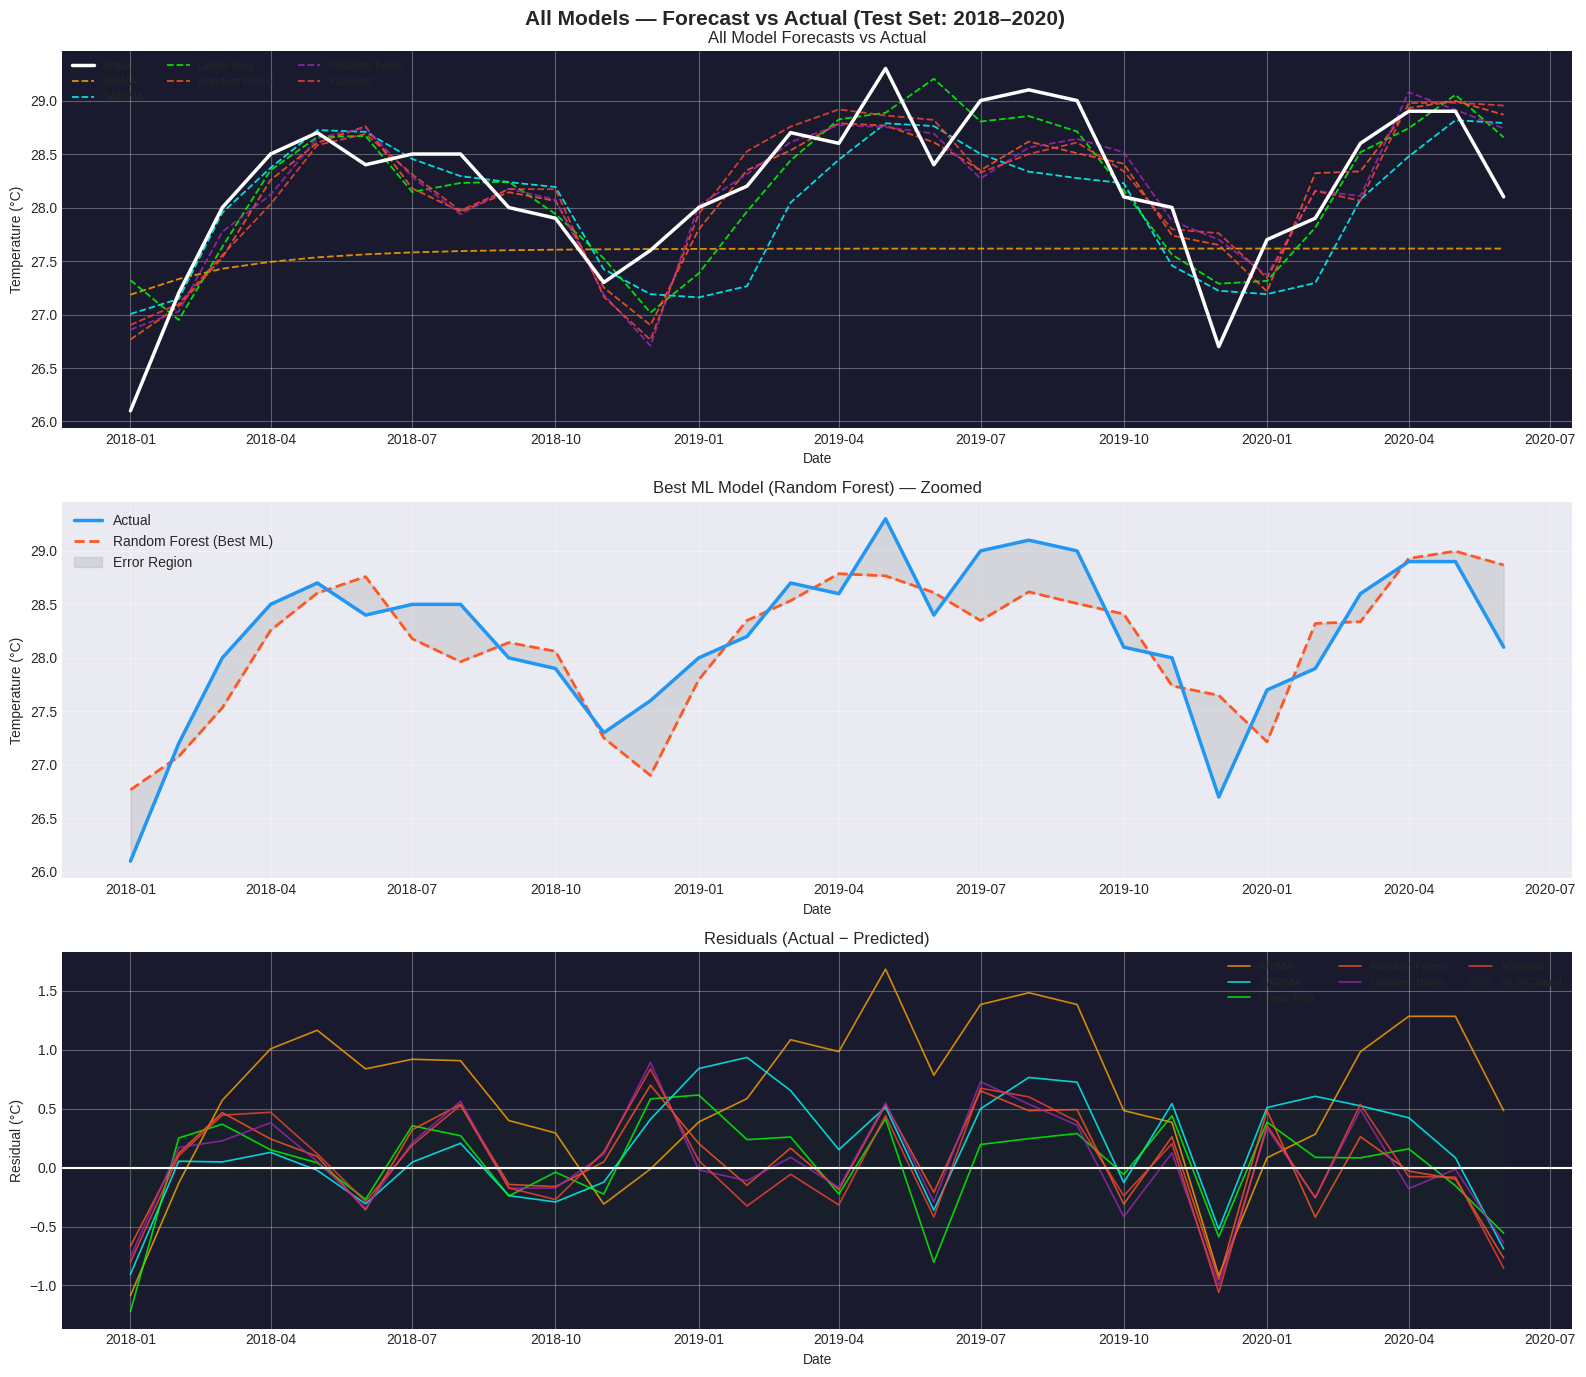

In [ ]:
sarima_pred = forecast_mean
lr_pred = pd.Series(predictions['Linear Regression'], index=test.index)
rf_pred = pd.Series(predictions['Random Forest'], index=test.index)
xgb_pred = pd.Series(predictions['XGBoost'], index=test.index)
gb_pred = pd.Series(predictions['Gradient Boosting'], index=test.index)
if 'Gradient Boosting' not in results:
    gb_metrics = evaluate_model(y_test.values, gb_pred)
    results['Gradient Boosting'] = gb_metrics
    predictions['Gradient Boosting'] = gb_pred.values
results_df = pd.DataFrame(results).T
results_df = results_df.round(4)
results_df.index.name = 'Model'
# Visualize
fig, axes = plt.subplots(3, 1, figsize=(16, 14))
fig.suptitle("All Models — Forecast vs Actual (Test Set: 2018–2020)",
             fontsize=15, fontweight='bold')

model_preds = {
    'ARIMA':            (arima_pred,  'orange'),
    'SARIMA':           (sarima_pred, 'cyan'),
    'Linear Reg.':      (lr_pred,     'lime'),
    'Random Forest':    (rf_pred,     '#FF5722'),
    'Gradient Boost':   (gb_pred,     '#9C27B0'),
    'XGBoost':          (xgb_pred,    '#F44336'),
}

#  Top: All forecasts
ax1 = axes[0]
ax1.plot(test.index, test.values, color='white', linewidth=2.5, zorder=10, label='Actual')
for name, (pred, color) in model_preds.items():
    ax1.plot(pred.index, pred.values, linewidth=1.3, linestyle='--', color=color,
             label=f'{name}', alpha=0.85)
ax1.set_title("All Model Forecasts vs Actual")
ax1.set_ylabel("Temperature (°C)")
ax1.legend(ncol=3, fontsize=8)
ax1.set_facecolor('#1a1a2e')
#  Middle: Best model (RF) zoomed
ax2 = axes[1]
ax2.plot(test.index, test.values, color=COLOR, linewidth=2.5, label='Actual', zorder=5)
ax2.plot(rf_pred.index, rf_pred.values, color=ACCENT, linewidth=2.0,
         linestyle='--', label='Random Forest (Best ML)')
ax2.fill_between(test.index, test.values, rf_pred.values,
                 alpha=0.2, color='gray', label='Error Region')
ax2.set_title("Best ML Model (Random Forest) — Zoomed")
ax2.set_ylabel("Temperature (°C)")
ax2.legend()
# Bottom: Residuals for all models
ax3 = axes[2]
for name, (pred, color) in model_preds.items():
    resid = test.values - pred.values
    ax3.plot(test.index, resid, color=color, linewidth=1.2, label=name, alpha=0.8)
ax3.axhline(0, color='white', linewidth=1.5, linestyle='-')
ax3.fill_between(test.index, -0.5, 0.5, alpha=0.05, color='green', label='±0.5°C band')
ax3.set_title("Residuals (Actual − Predicted)")
ax3.set_ylabel("Residual (°C)")
ax3.legend(ncol=3, fontsize=8)
ax3.set_facecolor('#1a1a2e')
for ax in axes:
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

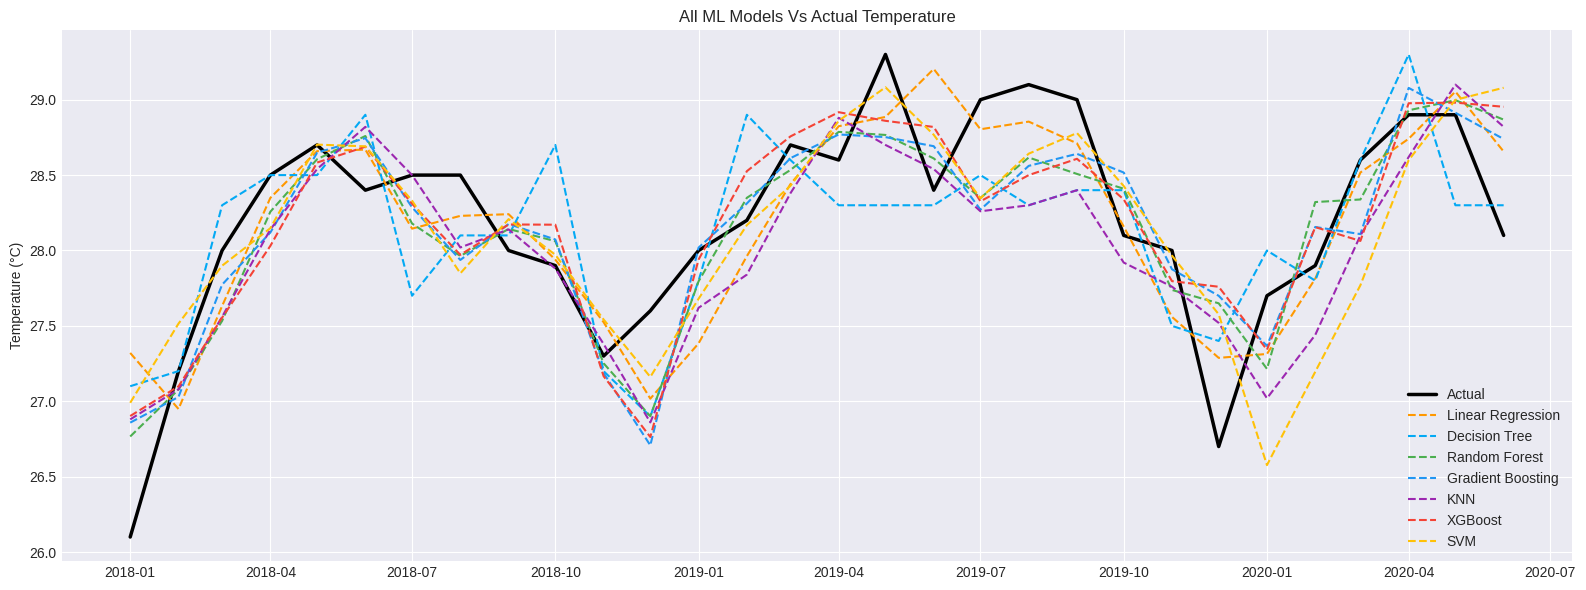

In [ ]:
# Plot-1 All ML Models Predictions Vs Actual
plt.figure(figsize=(16, 6))
plt.plot(y_test.index, y_test.values, color='black', linewidth=2.5, label='Actual')
plot_colors = ['#FF9800', '#03A9F4', '#4CAF50', '#2196F3', '#9C27B0', '#F44336', '#FFC107']
for (name, pred_array), color in zip(predictions.items(), plot_colors):
    pred_series = pd.Series(pred_array, index=test.index)
    plt.plot(pred_series.index, pred_series.values,
             label=name, linestyle='--', color=color, linewidth=1.5)
plt.title('All ML Models Vs Actual Temperature')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.show()

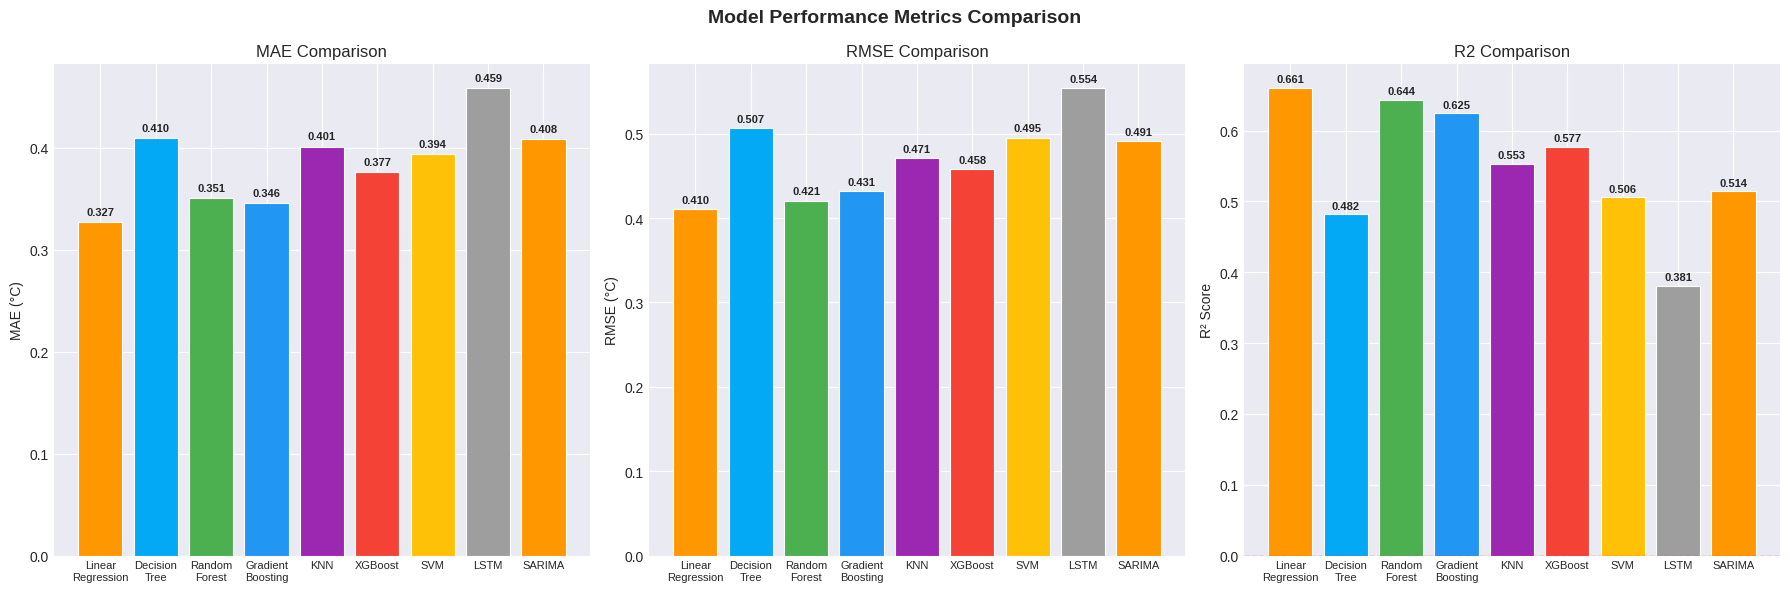

In [ ]:
# Metrics Bar Chart
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Model Performance Metrics Comparison", fontsize=14, fontweight='bold')

model_names = list(results_df.index)
bar_colors  = ['#FF9800','#03A9F4','#4CAF50','#2196F3','#9C27B0','#F44336', '#FFC107', '#9E9E9E'] # Added more colors for more models

for ax, metric, ylabel in zip(axes, ['MAE','RMSE','R2'],
                               ['MAE (°C)','RMSE (°C)','R² Score']):
    vals = [results_df.loc[m, metric] for m in model_names]
    bars = ax.bar(range(len(model_names)), vals, color=bar_colors[:len(model_names)], edgecolor='white', linewidth=0.8)
    ax.set_xticks(range(len(model_names)))
    ax.set_xticklabels([m.replace(' ','\n') for m in model_names], fontsize=8)
    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(ylabel)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')
    if metric == 'R2':
        ax.axhline(0, color='red', linestyle='--', linewidth=1.0, alpha=0.6)

plt.tight_layout()
plt.savefig('metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


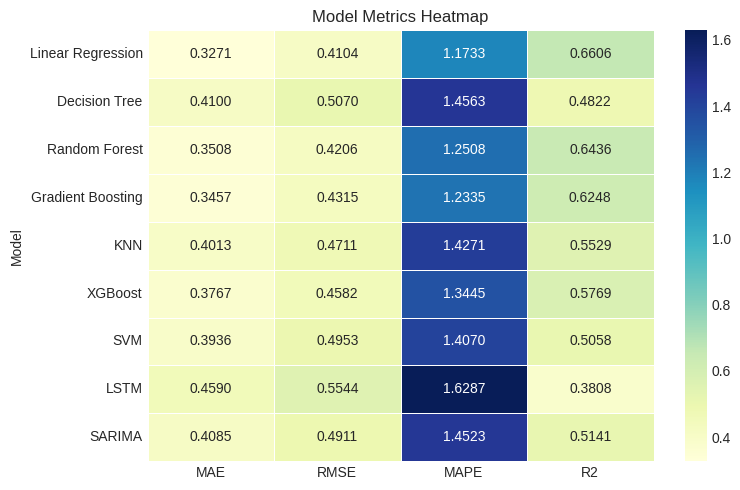

In [ ]:
# Heatmap for all Metrics
plt.figure(figsize = (8,5))
sns.heatmap(results_df.astype(float),
            annot = True, fmt = '.4f',cmap = 'YlGnBu',linewidth = 0.5)
plt.title('Model Metrics Heatmap')
plt.tight_layout()
plt.show()

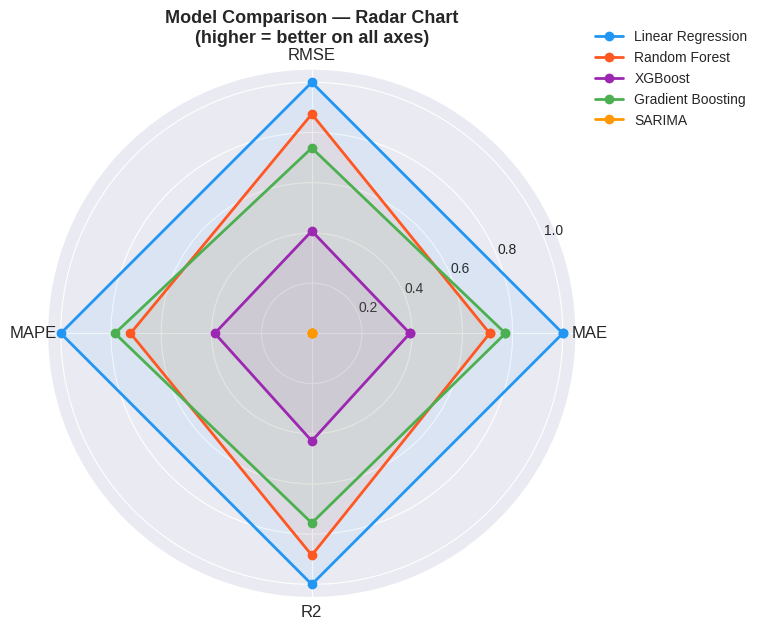

In [ ]:
from matplotlib.patches import FancyArrowPatch
import matplotlib.patches as mpatches

# Radar / Spider chart for top 5 models
top_models = ['Linear Regression', 'Random Forest', 'XGBoost',
              'Gradient Boosting', 'SARIMA']
metrics_radar = ['MAE', 'RMSE', 'MAPE', 'R2']

# Normalize: lower is better for MAE/RMSE/MAPE, higher for R2
radar_df = results_df.loc[top_models, metrics_radar].copy()
radar_df[['MAE','RMSE','MAPE']] = 1 - (radar_df[['MAE','RMSE','MAPE']] -
    radar_df[['MAE','RMSE','MAPE']].min()) / (
    radar_df[['MAE','RMSE','MAPE']].max() - radar_df[['MAE','RMSE','MAPE']].min())
radar_df['R2'] = (radar_df['R2'] - radar_df['R2'].min()) / (
    radar_df['R2'].max() - radar_df['R2'].min())

categories = metrics_radar
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = ['#2196F3','#FF5722','#9C27B0','#4CAF50','#FF9800']
for i, model in enumerate(top_models):
    values = radar_df.loc[model].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=model, color=colors[i])
    ax.fill(angles, values, alpha=0.07, color=colors[i])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=12)
ax.set_title('Model Comparison — Radar Chart\n(higher = better on all axes)',
             fontsize=13, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.show()

**Residual Error Analysis**

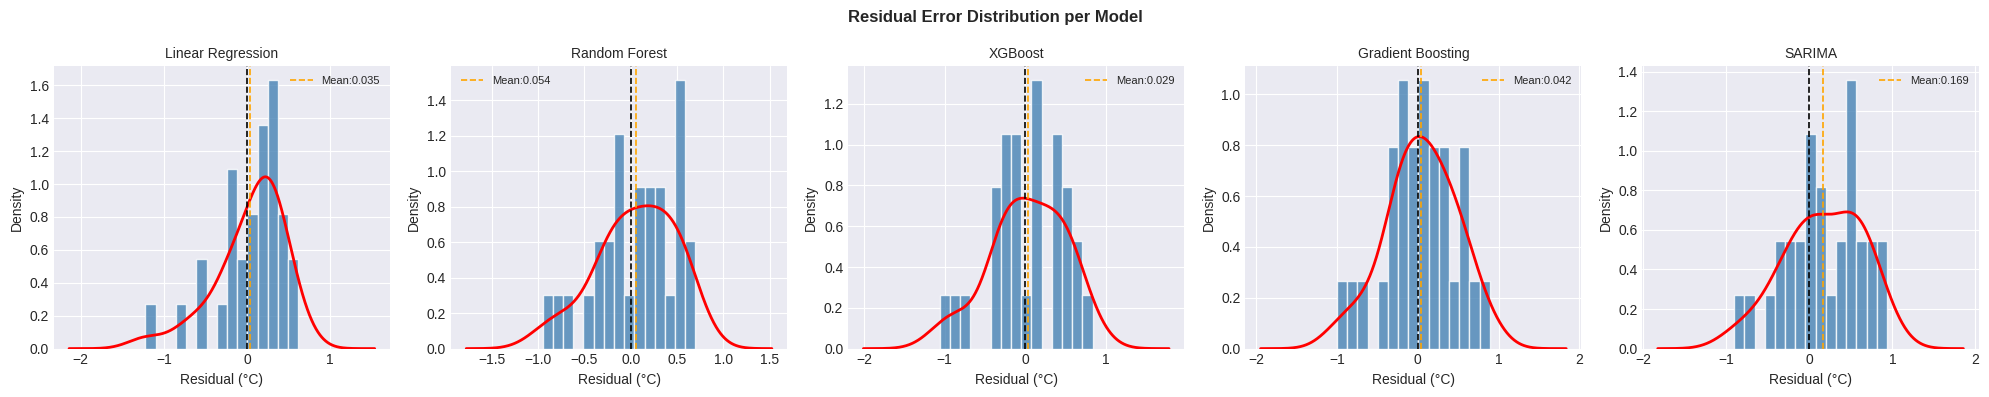

In [ ]:
# Residual Error Distribution per model
top_preds = {
    'Linear Regression': predictions['Linear Regression'],
    'Random Forest':     predictions['Random Forest'],
    'XGBoost':           predictions['XGBoost'],
    'Gradient Boosting': predictions['Gradient Boosting'],
    'SARIMA':            forecast_mean.values
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
fig.suptitle('Residual Error Distribution per Model', fontweight='bold')

for ax, (name, pred) in zip(axes, top_preds.items()):
    residuals = test.values - pred[:len(test)]
    ax.hist(residuals, bins=15, color='steelblue',
            edgecolor='white', alpha=0.8, density=True)
    residuals_series = pd.Series(residuals)
    residuals_series.plot(kind='kde', ax=ax, color='red', linewidth=2)
    ax.axvline(0, color='black', linestyle='--', linewidth=1.2)
    ax.axvline(residuals.mean(), color='orange', linestyle='--',
               linewidth=1.2, label=f'Mean:{residuals.mean():.3f}')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('Residual (°C)')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()



Residual analysis was performed to understand the errors produced by the forecasting models.

The residuals were analysed for:

- Prediction errors
- Systematic patterns
- Underprediction
- Overprediction
- Remaining temporal structure

Residual analysis helps determine whether the model has captured the major patterns in the temperature series.

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

cv_results = {name: {'MAE':[], 'RMSE':[], 'R2':[]}
              for name in ['Linear Regression','Random Forest','Gradient Boosting','XGBoost']}

models_cv = {
    'Linear Regression': LinearRegression(),
    'Random Forest':     RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'XGBoost':           XGBRegressor(n_estimators=100, random_state=42, verbosity=0),
}

X_all = data_featured[feature_cols]
y_all = data_featured['Temperature']

for fold, (tr_idx, te_idx) in enumerate(tscv.split(X_all), 1):
    Xtr, Xte = X_all.iloc[tr_idx], X_all.iloc[te_idx]
    ytr, yte = y_all.iloc[tr_idx], y_all.iloc[te_idx]
    for name, model in models_cv.items():
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)
        cv_results[name]['MAE'].append(mean_absolute_error(yte, pred))
        cv_results[name]['RMSE'].append(np.sqrt(mean_squared_error(yte, pred)))
        cv_results[name]['R2'].append(r2_score(yte, pred))

print(f"\n{'Model':<25} {'MAE Mean':>10} {'MAE Std':>10} {'RMSE Mean':>11} {'R² Mean':>9}")
print("-"*65)
for name, res in cv_results.items():
    print(f"{name:<25} {np.mean(res['MAE']):>10.4f} {np.std(res['MAE']):>10.4f} "
          f"{np.mean(res['RMSE']):>11.4f} {np.mean(res['R2']):>9.4f}")


Model                       MAE Mean    MAE Std   RMSE Mean   R² Mean
-----------------------------------------------------------------
Linear Regression             0.3562     0.0261      0.4452    0.6305
Random Forest                 0.3517     0.0411      0.4448    0.6291
Gradient Boosting             0.3537     0.0418      0.4469    0.6269
XGBoost                       0.3877     0.0466      0.4941    0.5435


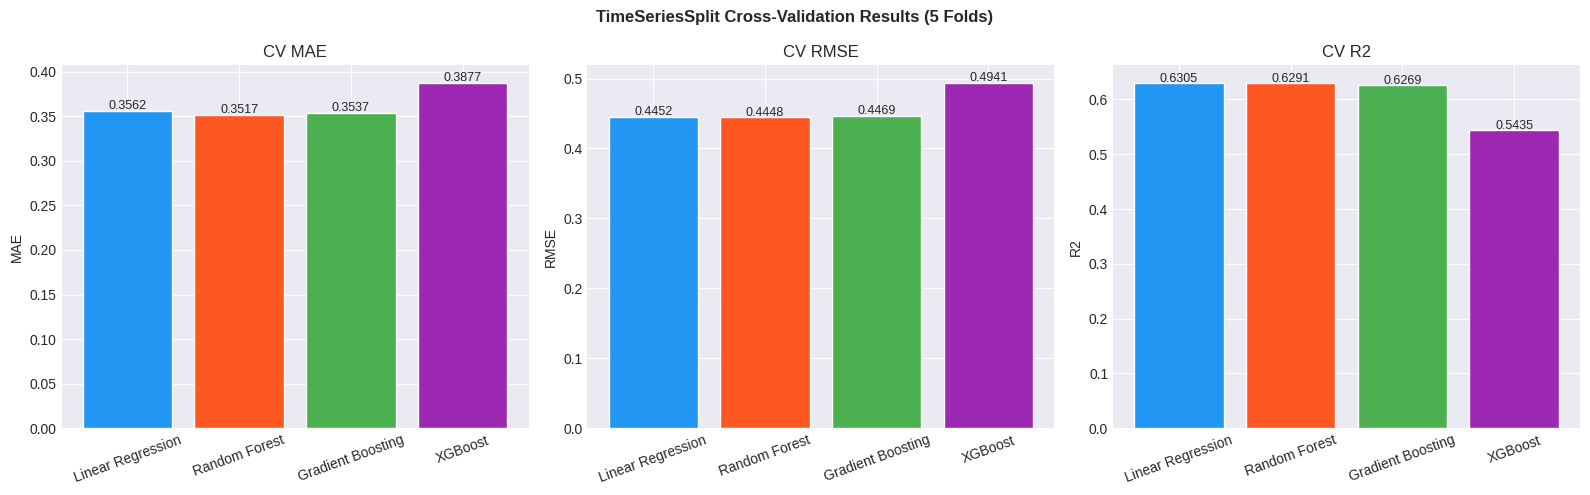

In [ ]:
# Cross Validation Results Plot
cv_summary = pd.DataFrame({
    name: {
        'MAE': np.mean(res['MAE']),
        'RMSE': np.mean(res['RMSE']),
        'R2': np.mean(res['R2'])
    }
    for name, res in cv_results.items()
}).T

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('TimeSeriesSplit Cross-Validation Results (5 Folds)', fontweight='bold')
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    bars = ax.bar(cv_summary.index, cv_summary[metric],
                  color=['#2196F3','#FF5722','#4CAF50','#9C27B0'],
                  edgecolor='white')
    ax.set_title(f'CV {metric}')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=20)
    for bar, val in zip(bars, cv_summary[metric]):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.002,
                f'{val:.4f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**Walk-Forward Validation**

Walk-Forward Validation — Random Forest
MAE  : 0.3661°C
RMSE : 0.4359°C
R²   : 0.6171


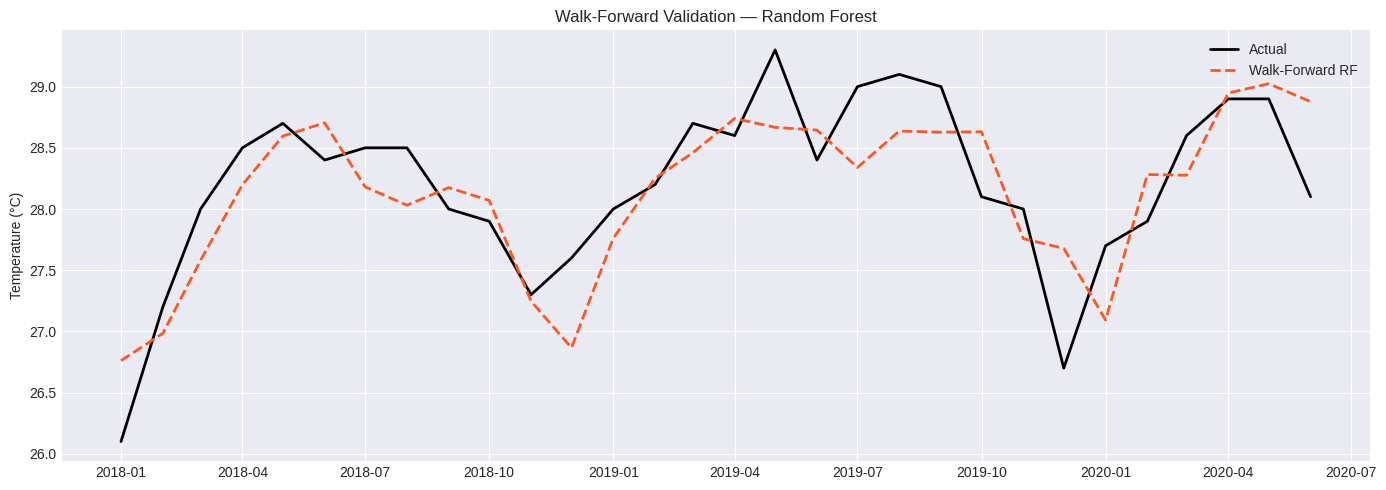

In [ ]:
from sklearn.ensemble import RandomForestRegressor

wf_predictions = []
wf_actuals = []

# Start with 80% training, expand one step at a time
initial_train_size = len(data_featured) - len(X_test)

for i in range(len(X_test)):
    X_wf_train = data_featured[feature_cols].iloc[:initial_train_size + i]
    y_wf_train = data_featured['Temperature'].iloc[:initial_train_size + i]
    X_wf_test  = data_featured[feature_cols].iloc[[initial_train_size + i]]
    y_wf_actual = data_featured['Temperature'].iloc[initial_train_size + i]

    wf_model = RandomForestRegressor(n_estimators=100, random_state=42)
    wf_model.fit(X_wf_train, y_wf_train)
    wf_pred = wf_model.predict(X_wf_test)[0]

    wf_predictions.append(wf_pred)
    wf_actuals.append(y_wf_actual)

wf_mae  = mean_absolute_error(wf_actuals, wf_predictions)
wf_rmse = np.sqrt(mean_squared_error(wf_actuals, wf_predictions))
wf_r2   = r2_score(wf_actuals, wf_predictions)

print(f"Walk-Forward Validation — Random Forest")
print(f"MAE  : {wf_mae:.4f}°C")
print(f"RMSE : {wf_rmse:.4f}°C")
print(f"R²   : {wf_r2:.4f}")

# Plot
plt.figure(figsize=(14, 5))
plt.plot(test.index, wf_actuals, color='black',
         linewidth=2, label='Actual')
plt.plot(test.index, wf_predictions, color='#FF5722',
         linestyle='--', linewidth=2, label='Walk-Forward RF')
plt.title('Walk-Forward Validation — Random Forest')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.tight_layout()
plt.show()


Walk-forward validation was performed to simulate real-world forecasting.

The model is trained using historical observations and predicts the next observation.

The training window is then updated with new observations before generating the next prediction.

This provides a more realistic evaluation of forecasting performance over time.

## 🔍 Feature Importance Analysis


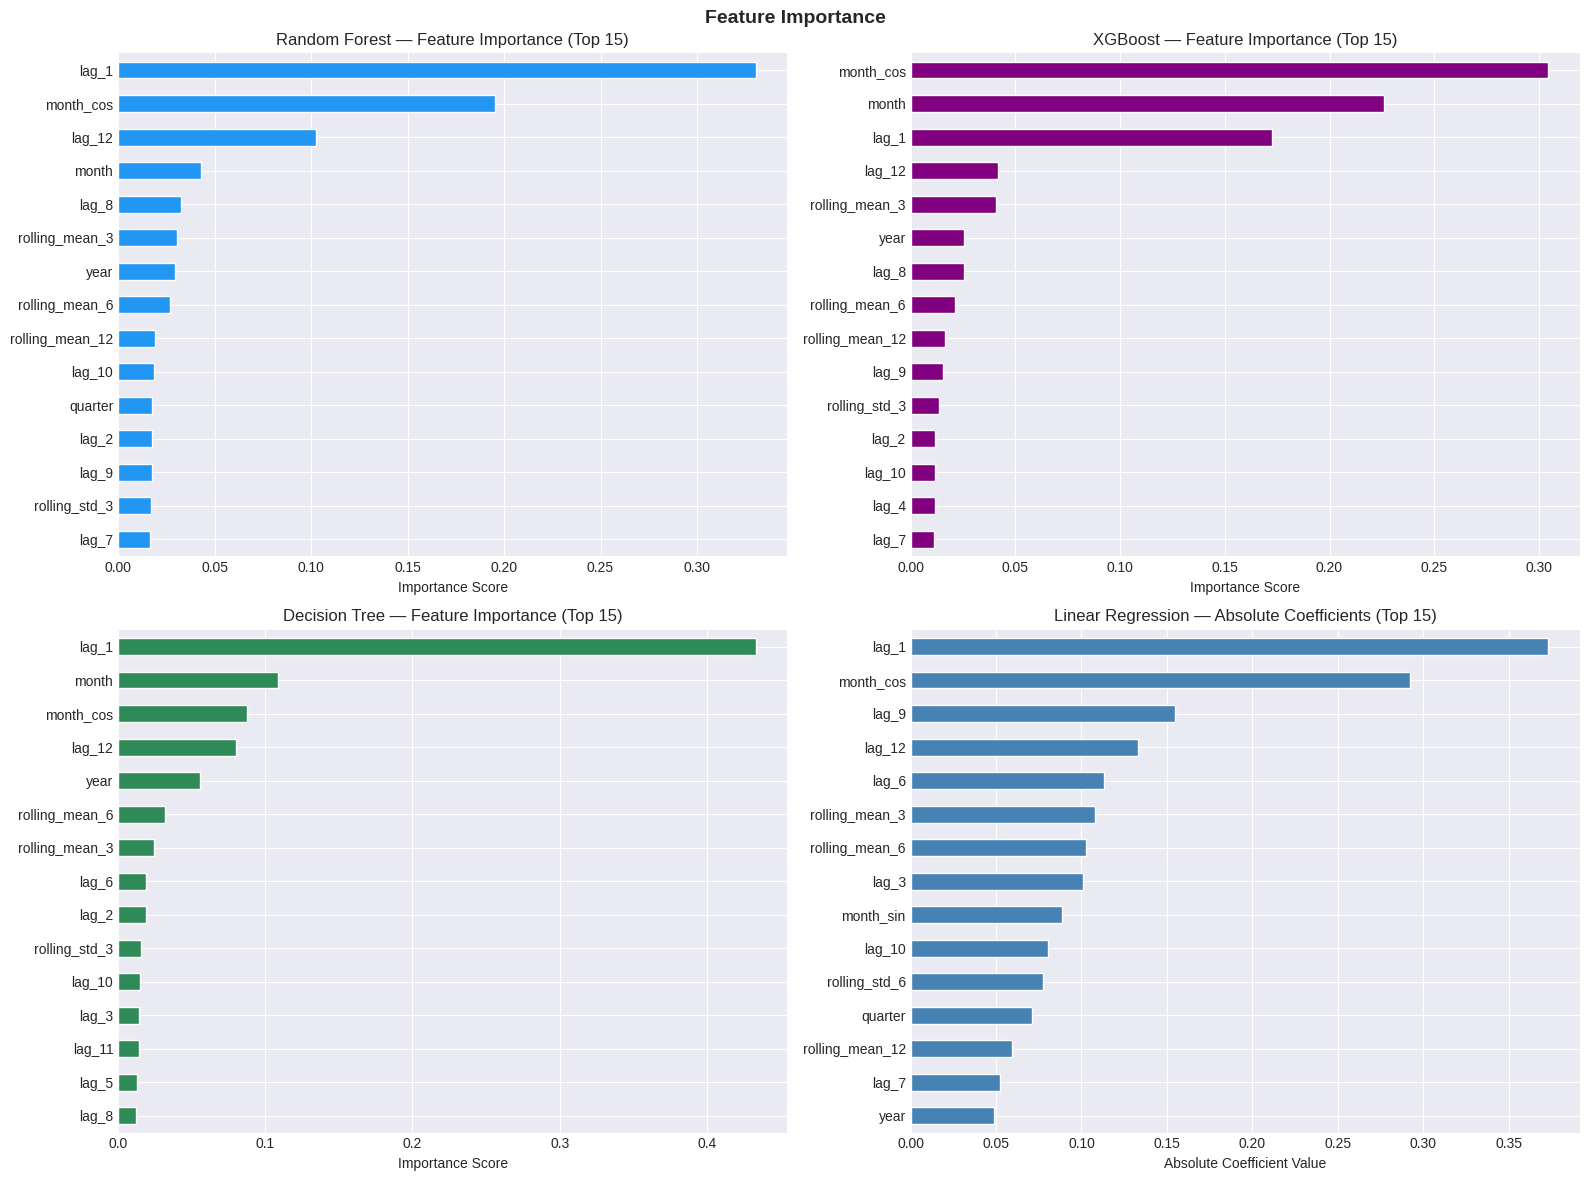

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Feature Importance", fontsize=14, fontweight='bold')

# Instantiate and fit models to get feature importances
rf_model = RandomForestRegressor(n_estimators=200,max_depth=10,random_state=42)
rf_model.fit(X_train_scaled, y_train_scaled)

xgb_model = XGBRegressor(n_estimators = 200,learning_rate = 0.05,max_depth =5,random_state = 42,verbosity = 0)
xgb_model.fit(X_train_scaled, y_train_scaled)

dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train_scaled, y_train_scaled)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train_scaled)

# Random Forest
rf_imp = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
rf_imp.tail(15).plot(kind='barh', ax=axes[0,0], color=COLOR, edgecolor='white')
axes[0,0].set_title("Random Forest — Feature Importance (Top 15)")
axes[0,0].set_xlabel("Importance Score")

#  XGBoost
xgb_imp = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
xgb_imp.tail(15).plot(kind='barh', ax=axes[0,1], color='purple', edgecolor='white')
axes[0,1].set_title("XGBoost — Feature Importance (Top 15)")
axes[0,1].set_xlabel("Importance Score")

# Decision Tree
dt_imp = pd.Series(dt_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
dt_imp.tail(15).plot(kind='barh', ax=axes[1,0], color='seagreen', edgecolor='white')
axes[1,0].set_title("Decision Tree — Feature Importance (Top 15)")
axes[1,0].set_xlabel("Importance Score")

# Linear Regression Coefficients
lr_coef = pd.Series(lr_model.coef_, index=feature_cols).abs().sort_values(ascending=True)
lr_coef.tail(15).plot(kind='barh', ax=axes[1,1], color='steelblue', edgecolor='white')
axes[1,1].set_title("Linear Regression — Absolute Coefficients (Top 15)")
axes[1,1].set_xlabel("Absolute Coefficient Value")

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


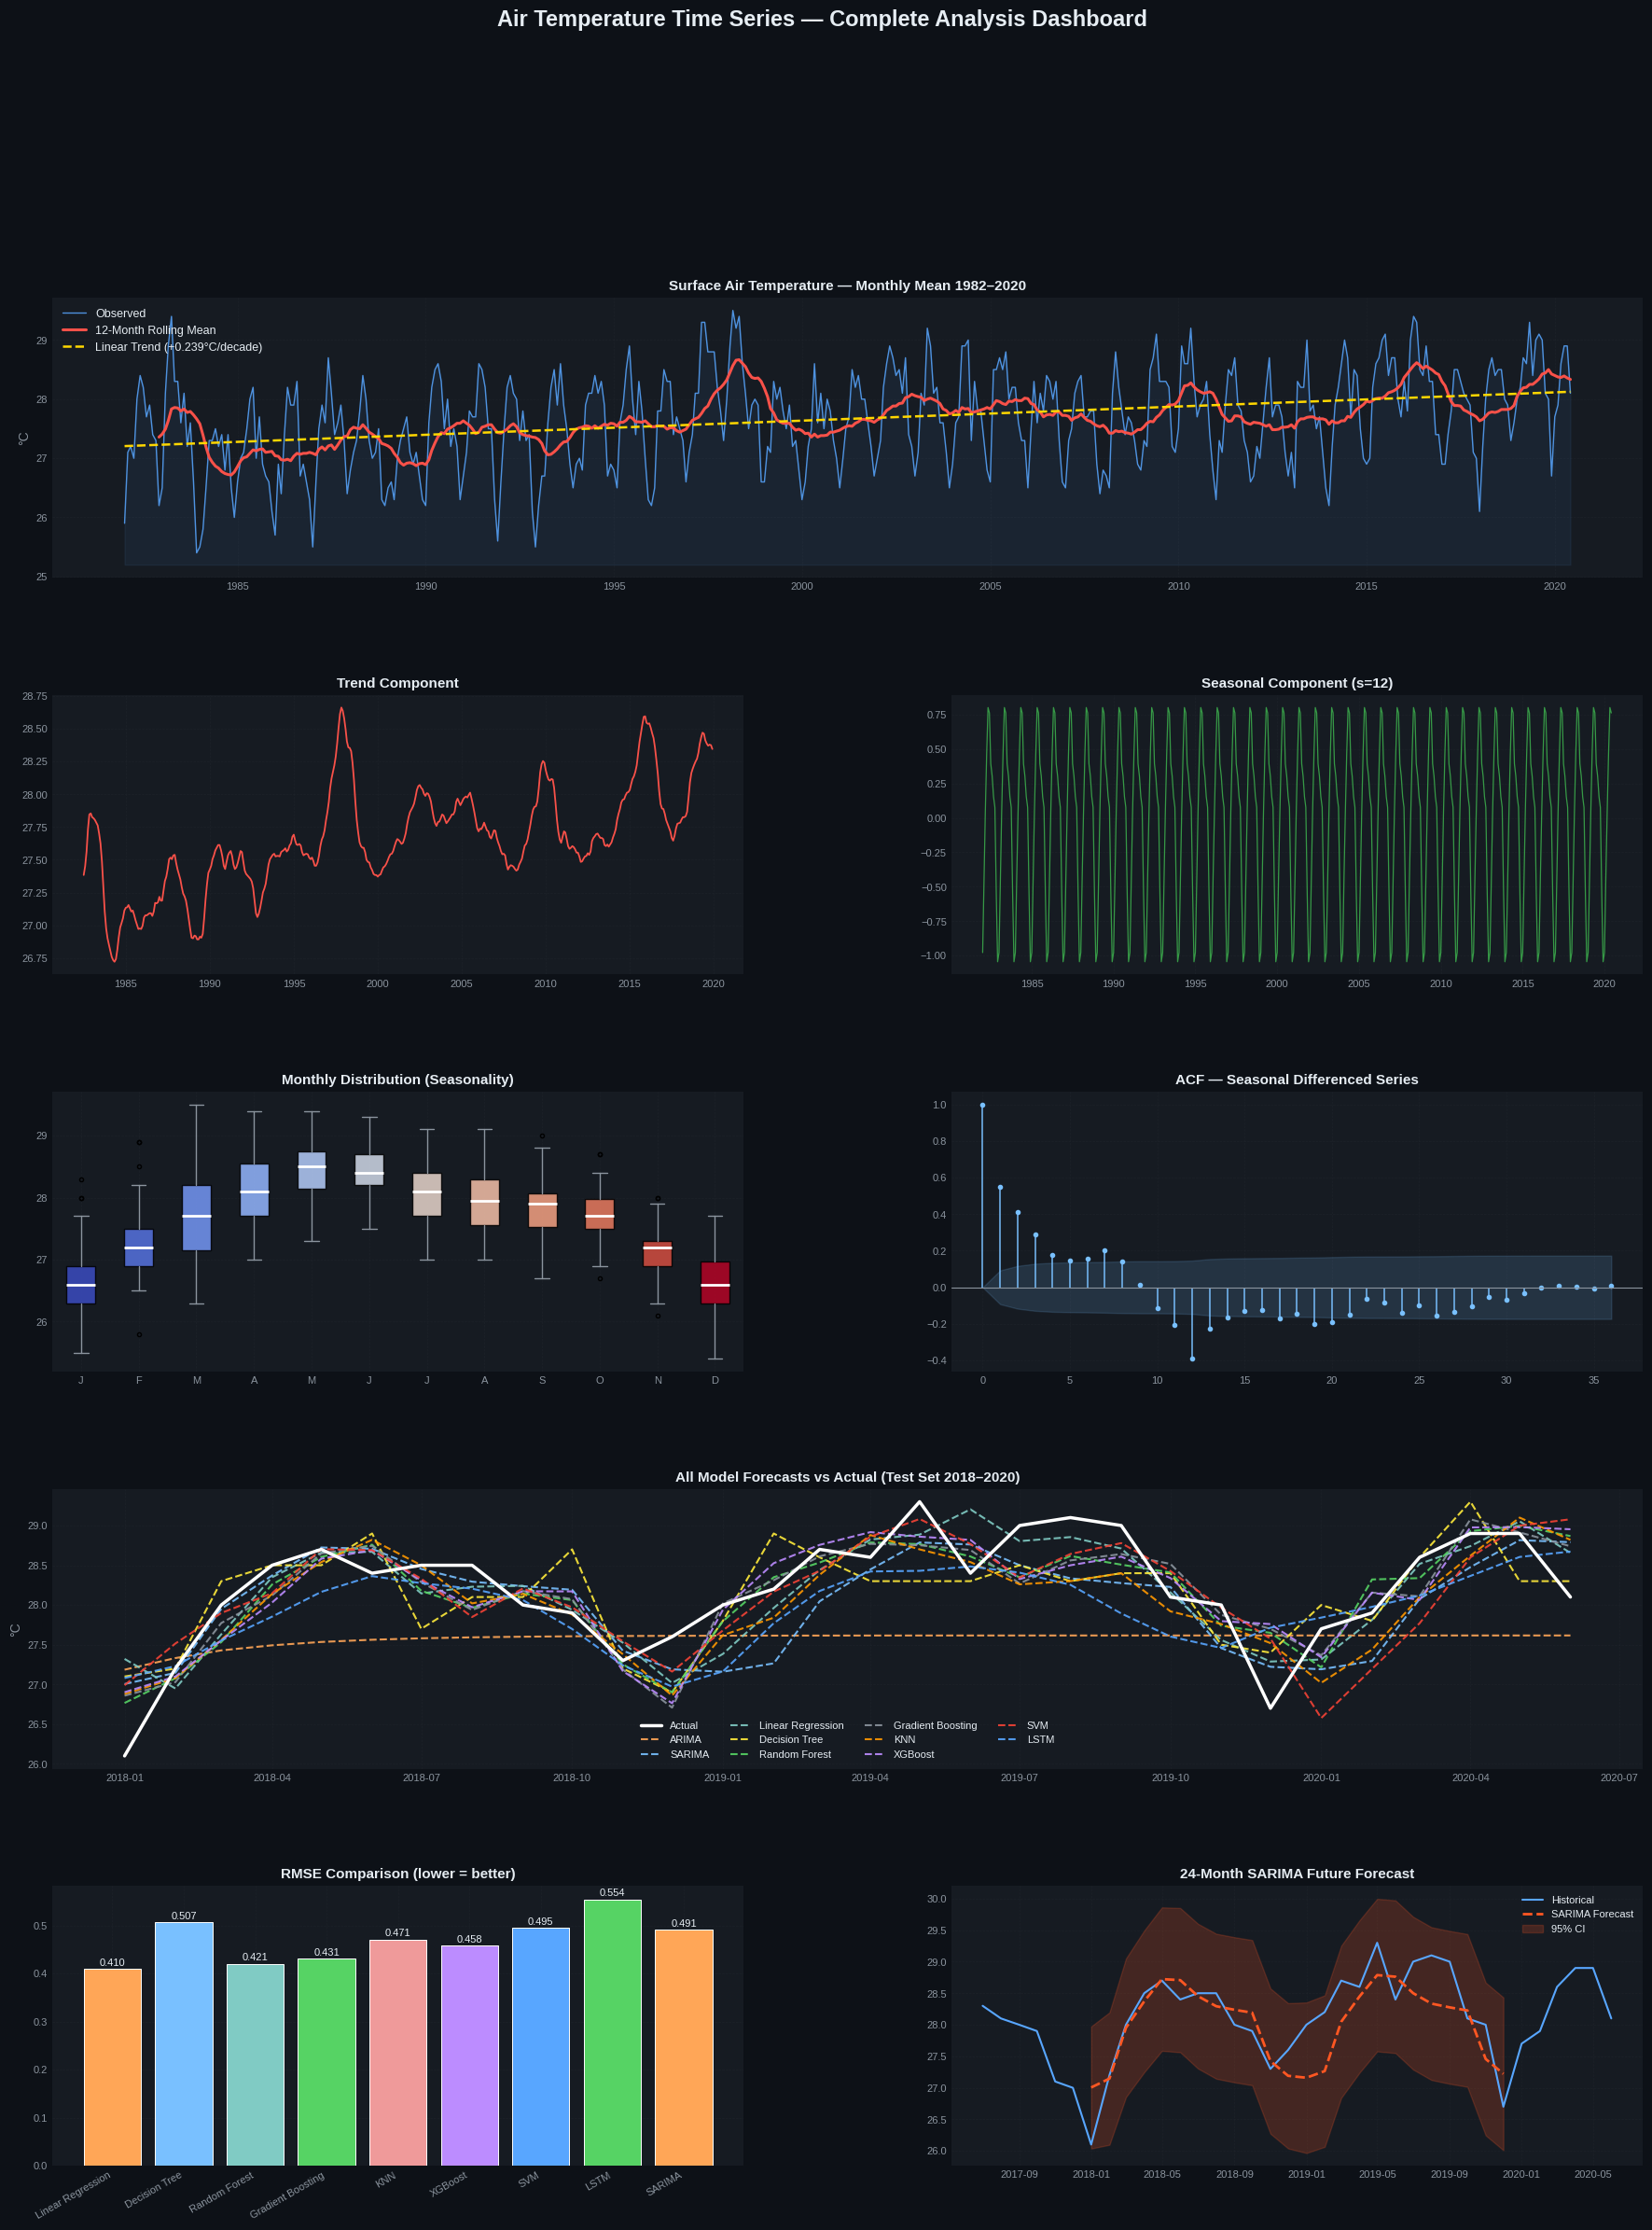

In [ ]:
fig = plt.figure(figsize=(22, 26), facecolor='#0d1117')
gs  = gridspec.GridSpec(5, 2, figure=fig, hspace=0.42, wspace=0.3)

C = {
    'bg':    '#0d1117',   'card':  '#161b22',
    'text':  '#e6edf3',   'sub':   '#8b949e',
    'grid':  '#21262d',   'line':  '#58a6ff',
    'trend': '#f85149',   'sea':   '#3fb950',
    'res':   '#bc8cff',   'sarima':'#79c0ff',
    'rf':    '#56d364',   'arima': '#ffa657',
}

def style(ax, title):
    ax.set_facecolor(C['card'])
    ax.set_title(title, color=C['text'], fontsize=11, fontweight='bold', pad=6)
    ax.tick_params(colors=C['sub'], labelsize=8)
    ax.grid(True, color=C['grid'], alpha=0.6, linestyle='--', linewidth=0.5)
    for sp in ax.spines.values(): sp.set_color(C['grid'])
    ax.xaxis.label.set_color(C['sub'])
    ax.yaxis.label.set_color(C['sub'])

#  1. Raw series + trend (full width)
ax1 = fig.add_subplot(gs[0,:])
ax1.plot(series.index, series, color=C['line'], linewidth=1.0, alpha=0.85, label='Observed')
ax1.plot(series.rolling(12).mean(), color=C['trend'], linewidth=2.2, label='12-Month Rolling Mean')
z2  = np.polyfit(range(len(series)), series.values, 1)
ax1.plot(series.index, np.poly1d(z2)(range(len(series))), color='gold',
         linewidth=1.8, linestyle='--', label=f'Linear Trend (+{z2[0]*120:.3f}°C/decade)')
ax1.fill_between(series.index, series.min()-0.2, series, alpha=0.07, color=C['line'])
style(ax1, 'Surface Air Temperature — Monthly Mean 1982–2020')
ax1.set_ylabel("°C", color=C['sub'])
ax1.legend(facecolor=C['card'], edgecolor=C['grid'], labelcolor=C['text'], fontsize=9)

# 2. Trend
ax2 = fig.add_subplot(gs[1,0])
ax2.plot(decomp.trend, color=C['trend'], linewidth=1.3)
style(ax2, 'Trend Component')

# 3. Seasonality
ax3 = fig.add_subplot(gs[1,1])
ax3.plot(decomp.seasonal, color=C['sea'], linewidth=0.9, alpha=0.8)
style(ax3, 'Seasonal Component (s=12)')

# 4. Monthly box
ax4 = fig.add_subplot(gs[2,0])
box_data = [series[series.index.month==m].values for m in range(1,13)]
bp = ax4.boxplot(box_data, patch_artist=True, medianprops=dict(color='white', linewidth=2),
                 whiskerprops=dict(color=C['sub']), capprops=dict(color=C['sub']),
                 flierprops=dict(marker='o', markersize=3, color=C['sub']))
for i, patch in enumerate(bp['boxes']):
    patch.set_facecolor(plt.cm.coolwarm(i/11))
    patch.set_alpha(0.85)
ax4.set_xticks(range(1,13))
ax4.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
style(ax4, 'Monthly Distribution (Seasonality)')

# 5. ACF after differencing
ax5 = fig.add_subplot(gs[2,1])
acf_vals, confint = acf(series_diff2.dropna(), nlags=36, alpha=0.05)
lags_ = np.arange(len(acf_vals))
ax5.vlines(lags_, [0], acf_vals, color=C['sarima'], linewidth=1.2, alpha=0.9)
ax5.plot(lags_, acf_vals, 'o', markersize=3, color=C['sarima'])
ax5.fill_between(lags_, confint[:,0]-acf_vals, confint[:,1]-acf_vals, alpha=0.15, color=C['sarima'])
ax5.axhline(0, color=C['sub'], linewidth=0.8)
style(ax5, 'ACF — Seasonal Differenced Series')

# Create model_preds dictionary for plotting all forecasts
model_preds = {}
model_preds['ARIMA'] = (arima_pred, arima_ci)
model_preds['SARIMA'] = (forecast_mean, conf_int)
for name, pred_array in predictions.items():
    model_preds[name] = (pd.Series(pred_array, index=test.index), None)

# Extend forecast_palette to include all ML models
forecast_palette = {
    'ARIMA': C['arima'],
    'SARIMA': C['sarima'],
    'Linear Regression': '#80cbc4',
    'Decision Tree': '#ffeb3b',
    'Random Forest': C['rf'],
    'KNN': '#ff9800',
    'XGBoost': C['res'],
    'SVM': '#f44336',
    'LSTM': C['line']
}

# 6. All forecasts vs actual
ax6 = fig.add_subplot(gs[3,:])
ax6.plot(test.index, test.values, color='white', linewidth=2.5, zorder=10, label='Actual')
for name, (pred_series, _conf_int) in model_preds.items():
    ax6.plot(pred_series.index, pred_series.values, color=forecast_palette.get(name, C['sub']), linewidth=1.5, linestyle='--',
             label=f'{name}', alpha=0.9)
style(ax6, 'All Model Forecasts vs Actual (Test Set 2018–2020)')
ax6.set_ylabel("°C", color=C['sub'])
ax6.legend(facecolor=C['card'], edgecolor=C['grid'], labelcolor=C['text'], fontsize=8, ncol=4)

#  7. Metrics bars
ax7 = fig.add_subplot(gs[4,0])
mdf = results_df.reset_index() # Corrected from metrics_df to results_df
bar_c = ['#ffa657','#79c0ff','#80cbc4','#56d364','#ef9a9a','#bc8cff', C['line'], C['rf']]
bars  = ax7.bar(mdf['Model'], mdf['RMSE'], color=bar_c[:len(mdf)], edgecolor='white', linewidth=0.7)
for bar in bars:
    ax7.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
             f'{bar.get_height():.3f}', ha='center', va='bottom', color=C['text'], fontsize=8)
ax7.set_xticklabels(mdf['Model'], rotation=30, ha='right')
style(ax7, 'RMSE Comparison (lower = better)')

# 8. Future forecast
ax8 = fig.add_subplot(gs[4,1])
ax8.plot(series[-36:].index, series[-36:], color=C['line'], linewidth=1.5, label='Historical')
ax8.plot(future_mean.index,  future_mean,  color=ACCENT, linewidth=2.0,
         linestyle='--', label='SARIMA Forecast')
ax8.fill_between(future_ci.index, future_ci.iloc[:,0], future_ci.iloc[:,1],
                 alpha=0.2, color=ACCENT, label='95% CI')
style(ax8, '24-Month SARIMA Future Forecast')
ax8.legend(facecolor=C['card'], edgecolor=C['grid'], labelcolor=C['text'], fontsize=8)

fig.suptitle('Air Temperature Time Series — Complete Analysis Dashboard',
             color=C['text'], fontsize=17, fontweight='bold', y=0.999)

plt.savefig('final_dashboard.png', dpi=150, bbox_inches='tight', facecolor=C['bg'])
plt.show()





Feature importance analysis was performed to understand which engineered features contribute most to model predictions.

Feature importance was analysed using tree-based models such as:

- Random Forest
- XGBoost
- Decision Tree

Linear Regression coefficients were also analysed to understand the contribution of numerical features.

This improves the interpretability of the forecasting models.

## 🔑 Key Findings

- The temperature series shows a long-term warming tendency.
- A repeating annual seasonal pattern is present.
- Historical temperature values contain useful temporal dependencies.
- Lag features provide information about previous temperature behaviour.
- Rolling features capture short-term and medium-term temperature patterns.
- Calendar and cyclic features help represent seasonal behaviour.
- Multiple statistical and machine learning approaches were successfully evaluated.
- The 12-step sequence LSTM provides a way to model longer temporal dependencies.
- TimeSeriesSplit and walk-forward validation provide additional evaluation beyond a single train-test split.

# Conclusion

The **PRAICP-1003 Air Temperature Time Series Forecasting** project successfully analysed historical monthly Surface Air Temperature data from 1982 to 2020.

The project combined **Exploratory Data Analysis, Statistical Time-Series Modelling, Machine Learning, and Deep Learning** to understand and forecast temperature behaviour.

Trend analysis and seasonal analysis revealed important temporal patterns in the dataset. Stationarity testing, decomposition, and ACF/PACF analysis provided further understanding of the underlying time-series structure.

Multiple forecasting approaches including **ARIMA, SARIMA, Linear Regression, Decision Tree, Random Forest, Gradient Boosting, KNN, XGBoost, SVM, and LSTM** were developed and evaluated.

Feature engineering using lag, rolling, calendar, and cyclic variables enabled machine learning models to learn historical and seasonal temperature relationships.

An improved **12-step sequence LSTM** was also developed to capture longer temporal dependencies using the previous 12 months of observations.

Overall, the project demonstrates an end-to-end approach for **analysing, modelling, validating, and forecasting monthly temperature data** using modern data science and machine learning techniques.

# 🚀 Future Scope

The project can be further enhanced in the following areas:

### 1. Longer Forecast Horizon

Develop models for:

- 12-month forecasting
- 24-month forecasting
- 36-month forecasting
- Multi-year forecasting

### 2. Advanced Deep Learning

Explore advanced architectures such as:

- GRU
- Bidirectional LSTM
- CNN-LSTM
- Attention-based LSTM
- Transformer-based Time-Series Models

### 3. Hyperparameter Optimization

Apply:

- Grid Search
- Random Search
- Bayesian Optimization
- KerasTuner

for systematic model optimization.

### 4. Additional Weather Variables

Include additional variables such as:

- Rainfall
- Humidity
- Wind Speed
- Atmospheric Pressure
- Solar Radiation
- Sea Surface Temperature

### 5. Real-Time Forecasting

Develop a system that automatically receives new observations and generates updated temperature forecasts.

### 6. Model Deployment

Deploy the final forecasting model using:

- Flask / FastAPI
- Streamlit
- Docker
- Cloud Platforms

### 7. Automated Monitoring

A production system can automatically:

- Receive new temperature data
- Generate forecasts
- Monitor model performance
- Retrain models periodically
- Detect unusual temperature patterns
- Generate alerts